# Evaluación Sumativa 3 — Cierre y comunicación del proyecto
## Dataset: *E-Commerce Shipping Data* (entregas atrasadas)

**MCDI501 - Estadística Computacional para la Toma de Decisiones**
Magíster en Ciencia de Datos e Inteligencia Artificial, Universidad Andrés Bello
Equipo: José Ignacio Rodríguez, Yerko Gallardo Miranda y Sebastián Rojas Araya

Este cuaderno maestro cierra el proyecto. La Evaluación Sumativa 1 (S1) preguntó *¿qué características se asocian con el atraso y qué evidencia orienta una revisión operacional?* y la respondió con análisis exploratorio e inferencial. La Evaluación Sumativa 2 (S2) validó esas respuestas con remuestreo y simulación. Esta Evaluación Sumativa 3 (S3) aplica **regresión lineal múltiple** para imputar datos faltantes y **regresión logística** para clasificar el atraso. Cada decisión metodológica se fundamenta en un resultado de S1 o de S2.

| Sección | Contenido | Responsable |
|---|---|---|
| 0 | Configuración, datos, semilla, partición común y funciones compartidas | José |
| 1 | Punto de partida: hallazgos de S1 y S2 que guían cada decisión | José |
| 2 | Parte 1: datos faltantes, imputación por regresión y comparación de estrategias | Yerko |
| 3 | Parte 2: regresión logística (tres modelos, desempeño, selección, *bootstrap* y diagnóstico) | Sebastián; Yerko (3.4) |
| 4 | Parte 3: impacto de la estrategia de imputación en el modelo final | José |
| 5 | Síntesis y recomendaciones | José, con todo el equipo |

## 0. Configuración, datos, semilla y funciones compartidas

Los datos se leen desde S1 (`sumativa_1/data/raw/ecommerce_shipping.csv`) y se verifica su huella SHA-256 contra el registro de S1. Las cifras de referencia se leen desde las tablas publicadas de S1 (`sumativa_1/outputs/tablas/`), de S2 (`sumativa_2/outputs/`) y de la Formativa 2 (`formativa_2/outputs/tablas/`); no se recalculan.

**Semilla y flujos.** Toda la aleatoriedad usa la semilla de S2, registrada desde el *beacon* de aleatoriedad de la Universidad de Chile. De `SeedSequence(SEMILLA).spawn(10)` se derivan flujos independientes, en orden fijo:

- los hijos 0 a 6 son los de S2;
- el hijo 7 es el de la Formativa 2;
- el hijo **8** simula los faltantes de S3;
- el hijo **9** se reserva para el *bootstrap* de S3.

Así, reejecutar una sección no altera las demás.

**Partición común.** La partición 70/30 estratificada por el atraso se define **una sola vez** aquí, sobre los 10.999 envíos y con `random_state = SEMILLA`. Es la misma de la Formativa 2. Todas las estrategias de imputación y todos los modelos usan los mismos envíos de entrenamiento y prueba; en la estrategia de eliminación se usan los envíos que quedan de cada conjunto. Así las comparaciones de la Parte 3 no dependen del azar de la partición.

In [1]:
from pathlib import Path
import hashlib
import json
import platform
import time

import numpy as np
import pandas as pd
import scipy
import sklearn
import statsmodels
import statsmodels.api as sm
from scipy import stats
from IPython.display import display

# Raíz del repositorio: funciona al ejecutar desde el repositorio, sumativa_3/ o sus notebooks/
ubicacion = Path.cwd().resolve()
REPO = next((p for p in [ubicacion, *ubicacion.parents]
             if (p / 'sumativa_3/notebooks/sumativa_3_grupo1.ipynb').is_file()), None)
if REPO is None:
    raise FileNotFoundError('Ejecute desde el repositorio, sumativa_3/ o sus notebooks/.')
RAIZ, S1, S2, F2 = REPO / 'sumativa_3', REPO / 'sumativa_1', REPO / 'sumativa_2', REPO / 'formativa_2'
TABLAS, FIGURAS = RAIZ / 'outputs/tablas', RAIZ / 'outputs/figuras'
for carpeta in (TABLAS, FIGURAS):
    carpeta.mkdir(parents=True, exist_ok=True)

# Datos: el CSV debe ser el registrado en S1
DATOS = S1 / 'data/raw/ecommerce_shipping.csv'
registro_fuente = json.loads((S1 / 'docs/registro_fuente.json').read_text(encoding='utf-8'))
HUELLA_DATOS = hashlib.sha256(DATOS.read_bytes()).hexdigest()
assert HUELLA_DATOS in {registro_fuente['file']['sha256'], registro_fuente['file']['sha256_lf_normalized']}, \
    'El CSV no coincide con el registrado en S1.'
raw = pd.read_csv(DATOS, encoding='utf-8-sig')
NOMBRES = {
    'ID': 'id_envio', 'Warehouse_block': 'bloque_bodega', 'Mode_of_Shipment': 'modalidad_envio',
    'Customer_care_calls': 'llamadas_atencion', 'Customer_rating': 'calificacion_cliente',
    'Cost_of_the_Product': 'costo_producto', 'Prior_purchases': 'compras_previas',
    'Product_importance': 'importancia_producto', 'Gender': 'genero',
    'Discount_offered': 'descuento_ofrecido', 'Weight_in_gms': 'peso_gramos',
}
TARGET = 'entrega_atrasada'
df = raw.rename(columns=NOMBRES)
df[TARGET] = raw['Reached.on.Time_Y.N']
df = df.drop(columns='Reached.on.Time_Y.N')
n, n_atr = len(df), int(df[TARGET].sum())
assert (n, n_atr, n - n_atr) == (10_999, 6_563, 4_436), 'Los conteos no coinciden con S1.'

# Tipos de variables (S1): numéricas continuas o discretas y categóricas nominales u ordinales
NUMERICAS = ['peso_gramos', 'descuento_ofrecido', 'costo_producto', 'compras_previas', 'llamadas_atencion',
             'calificacion_cliente']
CATEGORICAS = ['importancia_producto', 'bloque_bodega', 'modalidad_envio', 'genero']

# Semilla de S2 (beacon de la Universidad de Chile), verificada contra su pulso
registro_semilla = json.loads((S2 / 'docs/registro_semilla.json').read_text(encoding='utf-8'))
SEMILLA = registro_semilla['semilla']
assert SEMILLA == int(registro_semilla['pulso']['outputValue'], 16) % 2**32, 'La semilla no corresponde al pulso.'
FLUJOS = ['bootstrap_parametros', 'permutaciones', 'bootstrap_coeficientes', 'montecarlo_lotes',   # 0-3: S2
          'montecarlo_empirico', 'sensibilidad_escenarios', 'sensibilidad_montecarlo',             # 4-6: S2
          'formativa2_faltantes',                                                                    # 7: F2
          's3_faltantes', 's3_bootstrap']                                                            # 8-9: S3
SEMILLAS_FLUJO = dict(zip(FLUJOS, np.random.SeedSequence(SEMILLA).spawn(len(FLUJOS))))


def generador(flujo):
    # Generador nuevo del flujo indicado: reejecutar una sección reproduce sus mismos números
    return np.random.default_rng(SEMILLAS_FLUJO[flujo])


VERSIONES = dict(python=platform.python_version(), numpy=np.__version__, pandas=pd.__version__, scipy=scipy.__version__,
                 statsmodels=statsmodels.__version__, sklearn=sklearn.__version__)
print(f'Datos: {DATOS.relative_to(REPO).as_posix()} (SHA-256 {HUELLA_DATOS[:12]}…)')
print(f'{n:,} envíos | atrasados: {n_atr:,} ({n_atr / n:.2%}) | puntuales: {n - n_atr:,}'.replace(',', '.'))
print(f'SEMILLA = {SEMILLA} | ' + ', '.join(f'{k} {v}' for k, v in VERSIONES.items()))

Datos: sumativa_1/data/raw/ecommerce_shipping.csv (SHA-256 dcdc3fd8f050…)
10.999 envíos | atrasados: 6.563 (59.67%) | puntuales: 4.436
SEMILLA = 1505514103 | python 3.14.4, numpy 2.5.3, pandas 3.0.6, scipy 1.18.1, statsmodels 0.15.0, sklearn 1.9.1


In [2]:
from sklearn.model_selection import train_test_split

# Partición común 70/30, estratificada por el atraso: misma de la Formativa 2 (mismos parámetros)
IDX_TRAIN, IDX_TEST = train_test_split(df.index, test_size=0.30, stratify=df[TARGET], random_state=SEMILLA)
IDX_TRAIN, IDX_TEST = pd.Index(sorted(IDX_TRAIN)), pd.Index(sorted(IDX_TEST))
assert (len(IDX_TRAIN), len(IDX_TEST)) == (7_699, 3_300) and IDX_TRAIN.intersection(IDX_TEST).empty
assert abs(df.loc[IDX_TRAIN, TARGET].mean() - df.loc[IDX_TEST, TARGET].mean()) < 0.005


def particionar(datos):
    # Entrenamiento y prueba de un dataset: los envíos de la partición común que siguen presentes en él
    return datos.loc[datos.index.intersection(IDX_TRAIN)], datos.loc[datos.index.intersection(IDX_TEST)]


pd.DataFrame({'envios': [len(IDX_TRAIN), len(IDX_TEST)],
              'tasa_atraso': [df.loc[IDX_TRAIN, TARGET].mean(), df.loc[IDX_TEST, TARGET].mean()]},
             index=['entrenamiento', 'prueba']).round(4)

,envios,tasa_atraso
entrenamiento,7699,0.5967
prueba,3300,0.5967


In [3]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter

# Convención de figuras de S1, S2 y F2: negro = referencia; azul = modelo o S3; terracota = destacado; gris punteado = umbrales
AZUL, TERRA, GRIS, VERDE, GRID = '#1f5f8b', '#d1603d', '#555555', '#41866a', '#e1e4e8'
ANCHO = 6.3   # pulgadas: ancho de texto del informe
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 300, 'savefig.bbox': 'tight', 'pdf.fonttype': 42,
    'figure.constrained_layout.use': True, 'font.family': 'serif', 'font.size': 9,
    'axes.titlesize': 9, 'axes.labelsize': 8.5, 'xtick.labelsize': 8, 'ytick.labelsize': 8,
    'legend.fontsize': 8, 'legend.frameon': False, 'axes.edgecolor': '#8c8578',
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.titlelocation': 'left',
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.6, 'axes.axisbelow': True,
})
ETIQ = {'peso_gramos': 'Peso', 'descuento_ofrecido': 'Descuento', 'costo_producto': 'Costo',
        'compras_previas': 'Compras previas', 'llamadas_atencion': 'Llamadas', 'calificacion_cliente': 'Calificación',
        'importancia_producto': 'Importancia', 'bloque_bodega': 'Bodega', 'modalidad_envio': 'Modalidad',
        'genero': 'Género', TARGET: 'Atraso'}


def num(x, dec=0):
    # Formato es-CL: punto de miles, coma decimal y signo menos tipográfico
    return f'{x:,.{dec}f}'.replace(',', '_').replace('.', ',').replace('_', '.').replace('-', '−')


def guardar(nombre, fig):
    # Exporta en PDF (vectorial, para LaTeX) y PNG
    for ext in ('pdf', 'png'):
        fig.savefig(FIGURAS / f'{nombre}.{ext}')
    plt.show()

### Funciones compartidas

Las usan varias partes, para que la preparación, el ajuste y las métricas sean **idénticos** en los tres modelos de la Parte 2, en el *bootstrap* (3.4) y en la comparación de estrategias de la Parte 3. Así, las diferencias entre resultados se deben a los datos o al modelo, y no al código.

| Función | Uso |
|---|---|
| `disenar(datos, numericas, categoricas, entrenamiento)` | Matriz de diseño: estandariza las numéricas con la media y la DE **del entrenamiento** y codifica las categóricas en *dummies* (*one-hot* sin la primera categoría), con niveles fijos. |
| `ajustar_logit(X, y)` | Regresión logística por máxima verosimilitud (`statsmodels.Logit`) con intercepto. |
| `tabla_odds_ratios(modelo, escalas)` | Coeficientes, EE, *z*, *p*, IC 95 % de Wald y OR, por 1 DE y en unidades naturales. |
| `metricas_clasificacion(y, p, umbral)` | Matriz de confusión, accuracy, precision, recall, F1, especificidad y AUC. |
| `intervalos_bootstrap(replicas, estimacion, valores_jk)` | IC percentil y BCa: la misma función de S2, validada contra `scipy.stats.bootstrap`. |

In [4]:
from scipy.stats import norm
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score, precision_score, recall_score,
                             roc_auc_score)

NIVELES = {c: sorted(df[c].astype(str).unique()) for c in CATEGORICAS}   # niveles fijos para todas las partes


def disenar(datos, numericas, categoricas, entrenamiento):
    # Matriz de diseño con parámetros del entrenamiento: numéricas estandarizadas y dummies sin la primera categoría
    media = entrenamiento[numericas].mean()
    de = entrenamiento[numericas].std(ddof=1)
    partes = [(datos[numericas] - media) / de]
    for c in categoricas:
        codif = pd.Categorical(datos[c].astype(str), categories=NIVELES[c])
        partes.append(pd.get_dummies(codif, prefix=c, drop_first=True, dtype=float).set_index(datos.index))
    return pd.concat(partes, axis=1)


def ajustar_logit(X, y):
    # Logit por máxima verosimilitud con intercepto; exige convergencia
    modelo = sm.Logit(y.astype(float), sm.add_constant(X, has_constant='add')).fit(disp=0, maxiter=200)
    if not modelo.mle_retvals['converged']:
        raise RuntimeError('El modelo logístico no convergió.')
    return modelo


def tabla_odds_ratios(modelo, escalas=None):
    # Coeficientes y OR con IC 95 % de Wald; escalas = {variable: (unidad, DE del entrenamiento, etiqueta)}
    ic = modelo.conf_int()
    tabla = pd.DataFrame({'coef': modelo.params, 'ee': modelo.bse, 'z': modelo.tvalues, 'p': modelo.pvalues,
                          'ic_inf': ic[0], 'ic_sup': ic[1]}).drop(index='const', errors='ignore')
    tabla['or'], tabla['or_inf'], tabla['or_sup'] = np.exp(tabla['coef']), np.exp(tabla['ic_inf']), np.exp(tabla['ic_sup'])
    for v, (unidad, de, etiqueta) in (escalas or {}).items():
        if v in tabla.index:   # OR por `unidad` en la escala original: exp(beta * unidad / DE)
            f = unidad / de
            tabla.loc[v, ['or_unidad', 'or_unidad_inf', 'or_unidad_sup']] = np.exp(tabla.loc[v, ['coef', 'ic_inf', 'ic_sup']].to_numpy(float) * f)
            tabla.loc[v, 'unidad'] = etiqueta
    return tabla


def metricas_clasificacion(y, p, umbral=0.5):
    # Métricas con umbral fijo y AUC (independiente del umbral)
    y, pred = np.asarray(y).astype(int), (np.asarray(p) >= umbral).astype(int)
    vn, fp, fn, vp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {'n': len(y), 'vp': vp, 'fp': fp, 'fn': fn, 'vn': vn, 'accuracy': accuracy_score(y, pred),
            'precision': precision_score(y, pred, zero_division=0), 'recall': recall_score(y, pred),
            'f1': f1_score(y, pred), 'especificidad': recall_score(y, pred, pos_label=0), 'auc': roc_auc_score(y, p)}


def intervalos_bootstrap(replicas, estimacion, valores_jk, tamanos=None, alfa=0.05):
    # Sesgo, EE, IC percentil y BCa (misma implementación de S2; aceleración por jackknife)
    rep = np.asarray(replicas, dtype=float)
    res = {'B': len(rep), 'sesgo': rep.mean() - estimacion, 'ee': rep.std(ddof=1),
           'ic_percentil_inf': np.quantile(rep, alfa / 2), 'ic_percentil_sup': np.quantile(rep, 1 - alfa / 2)}
    prop = (np.sum(rep < estimacion) + 0.5 * np.sum(rep == estimacion)) / len(rep)
    tamanos = [len(valores_jk)] if tamanos is None else list(tamanos)
    num_a = den_a = 0.0
    for v in np.split(np.asarray(valores_jk, dtype=float), np.cumsum(tamanos)[:-1]):
        u = (len(v) - 1) * (v.mean() - v)
        num_a += np.sum(u ** 3) / len(v) ** 3
        den_a += np.sum(u ** 2) / len(v) ** 2
    z0, a = norm.ppf(prop), num_a / (6 * den_a ** 1.5)
    z = norm.ppf([alfa / 2, 1 - alfa / 2])
    niveles = norm.cdf(z0 + (z0 + z) / (1 - a * (z0 + z)))
    res.update(z0=z0, aceleracion=a, ic_bca_inf=np.quantile(rep, niveles[0]), ic_bca_sup=np.quantile(rep, niveles[1]))
    return res


# Control de las funciones con los datos completos: reproduce el modelo de la Formativa 2 (mismos 4 predictores)
_tr, _te = particionar(df)
_cols = ['peso_gramos', 'descuento_ofrecido', 'costo_producto', 'compras_previas']
_m = ajustar_logit(disenar(_tr, _cols, [], _tr), _tr[TARGET])
_auc = metricas_clasificacion(_te[TARGET], _m.predict(sm.add_constant(disenar(_te, _cols, [], _tr))))['auc']
_auc_f2 = pd.read_csv(F2 / 'outputs/tablas/sensibilidad_modelo.csv', index_col=0).loc['datos originales (sin faltantes)', 'auc']
assert np.isclose(_auc, _auc_f2, atol=1e-10), 'Las funciones compartidas deben reproducir el AUC de la Formativa 2.'
print(f'Funciones compartidas verificadas: reproducen el AUC de la Formativa 2 con datos completos ({num(_auc, 4)}).')

Funciones compartidas verificadas: reproducen el AUC de la Formativa 2 con datos completos (0,7207).


## 1. Punto de partida: hallazgos de S1 y S2

Esta sección **no repite** análisis: lee los resultados publicados que fundamentan cada decisión de S3. La tabla resume el hilo conductor del proyecto.

| Hallazgo previo | Fuente | Decisión en S3 |
|---|---|---|
| La base no tiene valores faltantes (0 nulos en 10.999 envíos) | S1, `calidad_datos.csv` | Se simulan faltantes con un mecanismo conocido para ejercitar la imputación (Parte 1) |
| Matriz de Spearman entre las 5 variables numéricas | S1, `correlacion_spearman.csv` | Fuente de los predictores de cada regresión de imputación (Parte 1) |
| Estabilidad de cada correlación en 4 escenarios (completos, winsorización, exclusión IQR y descuento ≤ 10) | S2, `validacion_completa/tablas/sensibilidad_coeficientes.csv` | Se priorizan los predictores con correlación estable (Parte 1) |
| Extremos IQR válidos; winsorizar no cambia nada y excluir IQR cambia la población | S1 y S2 | Los outliers se conservan (Parte 2) |
| Correlaciones con el atraso y su estado validado; el descuento solo asocia por el segmento > 10, todo atrasado | S1 y S2, `resultados_validados.csv` | Modelos en el segmento ≤ 10 y regla para el segmento > 10 (Parte 2, recomendación de F2) |
| Modalidad sin asociación (T01); llamadas y calificación posiblemente posteriores a la entrega; envíos 1 a 3.135 todos atrasados | S1 y S2 | Exclusiones y candidatos de los modelos (Parte 2) |
| IC percentil y BCa validados, con B = 10.000 | S2 | Método de estabilidad del modelo final (3.4) |
| Logit de la Formativa 2: AUC 0,714; 0,52 con descuento ≤ 10 | Formativa 2 | Línea base y diagnóstico de linealidad (Parte 2) |

In [5]:
T1, T2V = S1 / 'outputs/tablas', S2 / 'outputs/validacion_completa/tablas'
calidad_s1 = pd.read_csv(T1 / 'calidad_datos.csv')
spearman_s1 = pd.read_csv(T1 / 'correlacion_spearman.csv', index_col=0)
cor_atraso_s1 = pd.read_csv(T1 / 'correlacion_dependiente_cuantitativas.csv').set_index('variable')
holm_s1 = pd.read_csv(T1 / 'contrastes_holm_7.csv').set_index('codigo')
validados_s2 = pd.read_csv(S2 / 'outputs/resultados_validados.csv').set_index('id')
sens_coef_s2 = pd.read_csv(T2V / 'sensibilidad_coeficientes.csv')
f2_modelo = pd.read_csv(F2 / 'outputs/tablas/sensibilidad_modelo.csv', index_col=0)

# 1) Faltantes en S1
faltantes_s1 = calidad_s1[calidad_s1['control'] == 'nulos_totales'][['control', 'variable', 'esperado', 'observado', 'detalle']]
assert int(faltantes_s1['observado'].iloc[0]) == 0 and df.isna().sum().sum() == 0

# 2) Estabilidad de cada correlación de Spearman entre variables numéricas (S1) en los escenarios de S2
rho = sens_coef_s2[sens_coef_s2['estimando'] == 'rho_spearman'].copy()
rho['excluye_cero'] = ~((rho['ic_inf'] <= 0) & (rho['ic_sup'] >= 0))
estabilidad = (rho.pivot_table(index='variable', columns='escenario', values='excluye_cero', aggfunc='first')
               .reindex(columns=['completos', 'winsor_01_99', 'exclusion_iqr', 'descuento_le10']))
estabilidad['estable_s2'] = estabilidad.all(axis=1)
pares = []
for par, fila in estabilidad.iterrows():
    a, b = par.split('|')
    if TARGET in (a, b):
        continue
    ic = rho[(rho['variable'] == par) & (rho['escenario'] == 'completos')].iloc[0]
    pares.append({'variable_1': a, 'variable_2': b, 'rho_s1': spearman_s1.loc[a, b], 'ic_s2_inf': ic['ic_inf'],
                  'ic_s2_sup': ic['ic_sup'], 'estable_s2': bool(fila['estable_s2']),
                  'escenarios_que_incluyen_cero': ', '.join(e for e in estabilidad.columns[:4] if not fila[e])})
pares_s1_s2 = pd.DataFrame(pares).sort_values('rho_s1', key=abs, ascending=False).reset_index(drop=True)
assert len(pares_s1_s2) == 10 and np.allclose(pares_s1_s2['rho_s1'], [rho.query("escenario == 'completos'").set_index('variable')
                                                                      .loc[f"{r.variable_1}|{r.variable_2}", 'estimacion_s1'] for r in pares_s1_s2.itertuples()])

# 3) Correlaciones con el atraso (S1) y su estado validado en S2
ID_COR = {'descuento_ofrecido': 'COR-1', 'peso_gramos': 'COR-2', 'costo_producto': 'COR-4', 'compras_previas': 'COR-5'}
atraso = pd.DataFrame({'r_punto_biserial_s1': cor_atraso_s1['r_punto_biserial'], 'rho_s1': cor_atraso_s1['rho_spearman'],
                       'estado_s2': [validados_s2.loc[ID_COR[v], 'estado'] if v in ID_COR else 'no evaluada en S2'
                                     for v in cor_atraso_s1.index]})

for nombre, tabla in [('punto_partida_pares_spearman', pares_s1_s2), ('punto_partida_correlaciones_atraso', atraso)]:
    tabla.to_csv(TABLAS / f'{nombre}.csv', index=nombre != 'punto_partida_pares_spearman')
print('Faltantes registrados en S1:')
display(faltantes_s1)
print('Correlaciones de Spearman entre variables numéricas (S1) y su estabilidad en los escenarios de S2:')
display(pares_s1_s2.round(3))
print('Correlaciones con el atraso (S1) y estado validado (S2):')
display(atraso.round(3))
print('Contrastes de S1 (valor p ajustado por Holm):')
display(holm_s1[['prueba', 'p_holm', 'decision_holm']])
print('Formativa 2 (modelo logístico de 4 predictores), AUC en prueba:')
display(f2_modelo[['n_prueba', 'auc', 'accuracy']].round(4))

Faltantes registrados en S1:


,control,variable,esperado,observado,detalle
1,nulos_totales,todas,0,0,Sin imputación ni faltantes artificiales


Correlaciones de Spearman entre variables numéricas (S1) y su estabilidad en los escenarios de S2:


,variable_1,variable_2,rho_s1,ic_s2_inf,ic_s2_sup,estable_s2,escenarios_que_incluyen_cero
0,descuento_ofrecido,peso_gramos,-0.316,-0.333,-0.298,False,descuento_le10
1,costo_producto,llamadas_atencion,0.294,0.275,0.312,True,
2,compras_previas,llamadas_atencion,0.273,0.256,0.290,True,
3,compras_previas,peso_gramos,-0.235,-0.253,-0.216,True,
4,llamadas_atencion,peso_gramos,-0.233,-0.252,-0.214,True,
5,compras_previas,costo_producto,0.194,0.176,0.212,True,
6,costo_producto,peso_gramos,-0.132,-0.152,-0.112,True,
7,costo_producto,descuento_ofrecido,-0.116,-0.134,-0.098,False,"exclusion_iqr, descuento_le10"
8,descuento_ofrecido,llamadas_atencion,-0.104,-0.123,-0.085,False,descuento_le10
9,compras_previas,descuento_ofrecido,-0.094,-0.112,-0.075,False,"exclusion_iqr, descuento_le10"


Correlaciones con el atraso (S1) y estado validado (S2):


,r_punto_biserial_s1,rho_s1,estado_s2
variable,,,
compras_previas,-0.056,-0.075,sensible
llamadas_atencion,-0.067,-0.064,no evaluada en S2
costo_producto,-0.074,-0.072,sensible
peso_gramos,-0.269,-0.266,"respaldado, magnitud sensible"
descuento_ofrecido,0.397,0.335,sensible


Contrastes de S1 (valor p ajustado por Holm):


,prueba,p_holm,decision_holm
codigo,,,
T01,Chi-cuadrado: modalidad y atraso,6.895488e-01,no se rechaza H0
T02,Welch: peso medio atrasadas vs puntuales,9.654651e-180,se rechaza H0
T03,Welch: descuento medio atrasadas vs puntuales,0.000000e+00,se rechaza H0
E1,Mann-Whitney U: peso atrasadas vs puntuales,1.359519e-170,se rechaza H0
E2,z dos proporciones: atraso importancia alta vs...,9.795259e-04,se rechaza H0
E3,z dos proporciones: atraso descuento > 10 vs <...,0.000000e+00,se rechaza H0
E4,Welch: costo medio atrasadas vs puntuales,3.107184e-14,se rechaza H0


Formativa 2 (modelo logístico de 4 predictores), AUC en prueba:


,n_prueba,auc,accuracy
principal (imputación por mediana),3300.0,0.7139,0.6282
"principal, prueba con descuento ≤ 10",2493.0,0.5205,0.5082
sin descuento,3300.0,0.6660,0.6167
casos completos (dropna),2651.0,0.7140,0.6273
datos originales (sin faltantes),3300.0,0.7207,0.6352


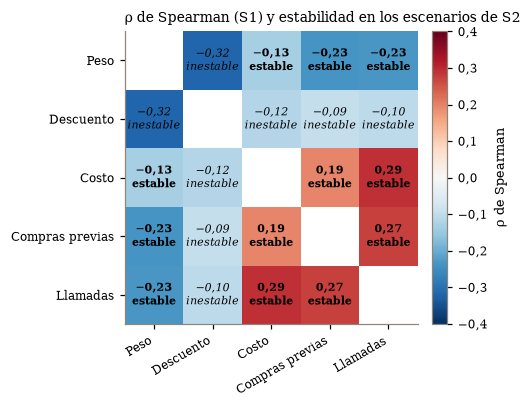

In [6]:
orden = ['peso_gramos', 'descuento_ofrecido', 'costo_producto', 'compras_previas', 'llamadas_atencion']
matriz = spearman_s1.loc[orden, orden]
estable = {frozenset((r.variable_1, r.variable_2)): r.estable_s2 for r in pares_s1_s2.itertuples()}
fig, ax = plt.subplots(figsize=(4.6, 3.8))
valores = matriz.to_numpy().copy()
np.fill_diagonal(valores, np.nan)   # la diagonal (rho = 1) no aporta información
im = ax.imshow(valores, cmap='RdBu_r', vmin=-0.4, vmax=0.4)
for i, a in enumerate(orden):
    for j, b in enumerate(orden):
        if i == j:
            continue
        ok = estable[frozenset((a, b))]
        ax.text(j, i, f"{num(matriz.loc[a, b], 2)}\n{'estable' if ok else 'inestable'}", ha='center', va='center',
                fontsize=7, color='black', fontweight='bold' if ok else 'normal', fontstyle='normal' if ok else 'italic')
ax.set_xticks(range(len(orden)), [ETIQ[v] for v in orden], rotation=30, ha='right')
ax.set_yticks(range(len(orden)), [ETIQ[v] for v in orden])
ax.grid(False)
ax.set_title('ρ de Spearman (S1) y estabilidad en los escenarios de S2')
fig.colorbar(im, ax=ax, shrink=0.8, label='ρ de Spearman', format=FuncFormatter(lambda v, _: num(v, 1)))
guardar('fig_0_matriz_estabilidad', fig)

#### Qué se lleva cada parte

- **Parte 1 (faltantes):**
  - S1 no registró faltantes, así que el análisis de faltantes parte de "0 % en todas las variables, sin patrón".
  - La matriz de Spearman y su estabilidad son la base para elegir los predictores de cada regresión de imputación. Las correlaciones **estables** forman el bloque peso–costo–compras previas–llamadas. Las del **descuento** con las demás variables numéricas son inestables: se anulan con descuento ≤ 10.
- **Parte 2 (logística):**
  - el peso es el único predictor con asociación robusta en todos los escenarios de S2;
  - el descuento es fuerte, pero depende del segmento > 10;
  - costo y compras previas son débiles y sensibles;
  - la modalidad no se asocia con el atraso (T01);
  - la Formativa 2 fija la línea base: AUC de 0,714.

## 2. Parte 1: datos faltantes e imputación

**Responsable:** Yerko · **Revisor:** Sebastián

**Rúbrica (21 pts):** usar explícitamente el análisis de faltantes de S1; imputación por regresión correcta; comparación sistemática de las tres estrategias; decisión justificada con solidez.

**Contenido:**
- **2.1** Faltantes en S1 (sección 1) y simulación MAR al 10 % en peso, costo, compras previas y descuento con `generador('s3_faltantes')`. La probabilidad de faltar depende solo de variables observadas, nunca del valor propio ni del atraso.
- **2.2** Una regresión lineal múltiple por variable, con 3 a 5 predictores de `pares_s1_s2` priorizados por `estable_s2`. Ajuste con casos completos, supuestos, desempeño y número de valores imputados.
- **2.3** Comparación de eliminación, mediana y regresión: *n*, distribuciones, preservación de la matriz de S1 y error frente al valor real. Decisión.

**Contrato (lo que esta parte deja definido para las siguientes):**
- `df_faltantes`: copia de `df` con los NaN simulados (mismo índice).
- `DATASETS = {'eliminacion': ..., 'mediana': ..., 'regresion': ...}`: tres DataFrames con las columnas de `df`, sin NaN y con el **índice original** de los envíos (la eliminación tiene menos filas).
- `ESTRATEGIA`: clave de `DATASETS` elegida para el resto de la evaluación.

### 2.1 Faltantes: punto de partida en S1 y simulación MAR

**Punto de partida (S1).** El control de calidad de S1 (`calidad_datos.csv`, citado en la sección 1) registró **0 valores faltantes** en las 12 columnas de los 10.999 envíos, por lo que no hay un patrón de faltantes observado que analizar. Para ejercitar la imputación se generan faltantes con un mecanismo **conocido y declarado de antemano**.

**Mecanismo: faltantes al azar condicionados a lo observado (MAR).** Se elimina cerca del 10 % de los valores de peso, costo, compras previas y descuento, las cuatro variables numéricas candidatas a predictor del atraso. La probabilidad de faltar es una función logística de variables **completas y observadas** (importancia, bodega, modalidad y género), con efectos distintos para cada variable. Por diseño:

- **no depende del valor propio**, porque eso sería un mecanismo no aleatorio (MNAR);
- **no depende del atraso**, porque eso contaminaría la evaluación de los modelos de la Parte 2.

El intercepto de cada logística se calibra para que la tasa media sea 10 %. Los sorteos son independientes entre variables, usan el flujo `s3_faltantes` y son reproducibles.

In [7]:
from scipy.optimize import brentq

# 2.1 Simulación de faltantes MAR al 10 %
VARS_FALTANTES = ['peso_gramos', 'costo_producto', 'compras_previas', 'descuento_ofrecido']
TASA_FALTANTES = 0.10

# Mecanismo declarado de antemano: efecto (en log-odds) de categorías observadas sobre P(faltar).
# Solo usa variables completas; nunca el valor propio (sería MNAR) ni el atraso (contaminaría la evaluación).
MECANISMO = {
    'peso_gramos':        {'importancia_producto': {'high': 0.8}, 'modalidad_envio': {'Ship': 0.5}},
    'costo_producto':     {'bloque_bodega': {'F': 0.7}, 'genero': {'M': 0.4}},
    'compras_previas':    {'importancia_producto': {'low': 0.6}, 'modalidad_envio': {'Road': 0.6}},
    'descuento_ofrecido': {'bloque_bodega': {'A': 0.6, 'B': 0.6}, 'genero': {'F': 0.4}},
}


def prob_faltar(datos, efectos, tasa):
    # P(faltar) = logística(intercepto + efectos); el intercepto se calibra para que la media sea `tasa`
    puntaje = sum(datos[c].map(niveles).fillna(0.0) for c, niveles in efectos.items())
    intercepto = brentq(lambda b0: (1 / (1 + np.exp(-(b0 + puntaje)))).mean() - tasa, -10, 10)
    return 1 / (1 + np.exp(-(intercepto + puntaje)))


rng = generador('s3_faltantes')
df_faltantes = df.copy()
MASCARA = pd.DataFrame(False, index=df.index, columns=VARS_FALTANTES)   # True = valor eliminado
for v in VARS_FALTANTES:   # sorteo independiente por variable: una fila puede faltar en varias
    MASCARA[v] = rng.random(len(df)) < prob_faltar(df, MECANISMO[v], TASA_FALTANTES)
    df_faltantes.loc[MASCARA[v], v] = np.nan
assert df_faltantes.drop(columns=VARS_FALTANTES).notna().all().all(), 'Solo deben faltar las 4 variables.'

# Resumen por variable y por fila
resumen_faltantes = pd.DataFrame({'faltantes': MASCARA.sum(), 'pct': MASCARA.mean() * 100,
                                  'observados': (~MASCARA).sum()})
por_fila = (MASCARA.sum(axis=1).value_counts().sort_index()
            .rename_axis('variables_faltantes_en_la_fila').to_frame('filas'))
por_fila['pct'] = por_fila['filas'] / len(df) * 100
filas_incompletas = int(MASCARA.any(axis=1).sum())

resumen_faltantes.to_csv(TABLAS / 'faltantes_resumen_variables.csv')
por_fila.to_csv(TABLAS / 'faltantes_resumen_filas.csv')
print(f'Faltantes simulados por variable (MAR, objetivo {num(TASA_FALTANTES * 100)} %):')
display(resumen_faltantes.round(2))
print('Faltantes por fila:')
display(por_fila.round(2))
print(f'Filas con al menos un faltante: {num(filas_incompletas)} ({num(filas_incompletas / len(df) * 100, 1)} %) | '
      f'casos completos: {num(len(df) - filas_incompletas)}')

Faltantes simulados por variable (MAR, objetivo 10 %):


,faltantes,pct,observados
peso_gramos,1086,9.87,9913
costo_producto,1107,10.06,9892
compras_previas,1055,9.59,9944
descuento_ofrecido,1112,10.11,9887


Faltantes por fila:


,filas,pct
variables_faltantes_en_la_fila,,
0,7213,65.58
1,3245,29.50
2,508,4.62
3,33,0.30


Filas con al menos un faltante: 3.786 (34,4 %) | casos completos: 7.213


In [8]:
# Verificación del mecanismo con una regresión logística del indicador de faltante:
# (1) sobre las variables observadas: si fuera MCAR, la prueba de razón de verosimilitud (LR) no rechazaría;
# (2) agregando el valor propio: si fuera MNAR, su coeficiente sería significativo.
X_obs = disenar(df, [], CATEGORICAS, df)
filas = []
for v in VARS_FALTANTES:
    m_obs = ajustar_logit(X_obs, MASCARA[v])
    m_propio = ajustar_logit(pd.concat([X_obs, disenar(df, [v], [], df)], axis=1), MASCARA[v])
    filas.append({'variable': v, 'lr_chi2': m_obs.llr, 'gl': int(m_obs.df_model), 'p_lr': m_obs.llr_pvalue,
                  'pseudo_r2': m_obs.prsquared, 'p_valor_propio': m_propio.pvalues[v]})
verificacion_mar = pd.DataFrame(filas).set_index('variable')
verificacion_mar['conclusion'] = np.where(
    (verificacion_mar['p_lr'] < 0.05) & (verificacion_mar['p_valor_propio'] >= 0.05),
    'MAR: depende de lo observado, no del valor propio', 'revisar')
assert (verificacion_mar['conclusion'] != 'revisar').all()

verificacion_mar.to_csv(TABLAS / 'faltantes_verificacion_mar.csv')
print('Logit del indicador de faltante sobre importancia, bodega, modalidad y género:')
display(verificacion_mar.round(4))

Logit del indicador de faltante sobre importancia, bodega, modalidad y género:


,lr_chi2,gl,p_lr,pseudo_r2,p_valor_propio,conclusion
variable,,,,,,
peso_gramos,135.5064,9,0.0,0.0191,0.1676,"MAR: depende de lo observado, no del valor propio"
costo_producto,174.1718,9,0.0,0.0243,0.6024,"MAR: depende de lo observado, no del valor propio"
compras_previas,153.8271,9,0.0,0.0221,0.3159,"MAR: depende de lo observado, no del valor propio"
descuento_ofrecido,128.4281,9,0.0,0.0178,0.6519,"MAR: depende de lo observado, no del valor propio"


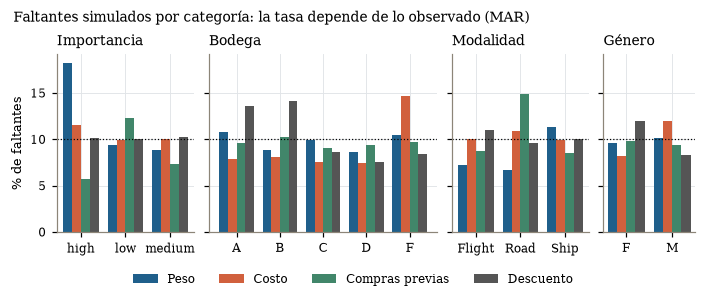

In [9]:
# Figura: % de faltantes por categoría observada (línea punteada = 10 % global)
fig, axes = plt.subplots(1, len(CATEGORICAS), figsize=(ANCHO, 2.6), sharey=True,
                         gridspec_kw={'width_ratios': [len(NIVELES[c]) for c in CATEGORICAS]})
colores = dict(zip(VARS_FALTANTES, [AZUL, TERRA, VERDE, GRIS]))
ancho = 0.8 / len(VARS_FALTANTES)
for ax, c in zip(axes, CATEGORICAS):
    tasas = MASCARA.groupby(df[c].astype(str)).mean().reindex(NIVELES[c]) * 100
    x = np.arange(len(NIVELES[c]))
    for k, v in enumerate(VARS_FALTANTES):
        ax.bar(x + (k - 1.5) * ancho, tasas[v], ancho, color=colores[v], label=ETIQ[v])
    ax.axhline(TASA_FALTANTES * 100, color='black', ls=':', lw=0.8)
    ax.set_xticks(x, NIVELES[c])
    ax.set_title(ETIQ[c])
axes[0].set_ylabel('% de faltantes')
axes[0].yaxis.set_major_formatter(FuncFormatter(lambda y, _: num(y)))
fig.legend(*axes[0].get_legend_handles_labels(), loc='outside lower center', ncol=4)
fig.suptitle('Faltantes simulados por categoría: la tasa depende de lo observado (MAR)', x=0.01, ha='left', fontsize=9)
guardar('fig_2_1_patron_faltantes', fig)

**Resultado.**

- **Faltantes por variable:** cada variable perdió entre 9,6 % y 10,1 % de sus valores: 1.086 en peso, 1.107 en costo, 1.055 en compras previas y 1.112 en descuento.
- **Faltantes por fila:** 3.786 envíos (34,4 %) tienen al menos un faltante, y solo quedan 7.213 casos completos. Es el costo que pagaría la eliminación de filas, y se compara en la sección 2.3.
- **El mecanismo es MAR.** La regresión logística del indicador de faltante sobre importancia, bodega, modalidad y género rechaza el mecanismo completamente al azar (MCAR) en las cuatro variables (prueba LR, p < 0,001). En cambio, el valor propio no agrega información una vez controladas las observadas (p entre 0,17 y 0,65), así que no hay indicios de MNAR. La figura muestra esa dependencia: por ejemplo, el peso falta un 18 % en importancia alta y el costo un 15 % en la bodega F.
- **Consecuencia para 2.2:** con un mecanismo MAR, la eliminación de filas pierde eficiencia y puede sesgar, y la imputación por regresión es adecuada porque usa la información observada.

### 2.2 Imputación por regresión lineal múltiple

Se ajusta **una regresión lineal múltiple por cada variable con faltantes**. Los predictores salen de la matriz de Spearman de S1 (sección 1) y se priorizan por su estabilidad en S2, con esta regla:

1. se incluyen las correlaciones **estables** en los cuatro escenarios de S2;
2. se agregan las inestables con |ρ| ≥ 0,30, por su magnitud;
3. si quedan menos de 3 predictores, se usan todas las candidatas.

Así, el **peso** suma el descuento (ρ = −0,32, la correlación más fuerte de S1) a sus tres predictores estables. El **descuento** no tiene ninguna correlación estable en S2, porque se anulan con descuento ≤ 10, y se imputa con las cuatro candidatas: es una **limitación declarada**. El atraso nunca es predictor, para evitar fuga hacia la Parte 2. Las llamadas sí se usan: están completas y aquí no importa su temporalidad.

**Ajuste:** mínimos cuadrados ordinarios (`statsmodels.OLS`) con los casos completos de cada variable y sus predictores.

**Supuestos:**

- linealidad y homocedasticidad: residuos frente a ajustados y prueba de Breusch-Pagan;
- normalidad: gráfico QQ y prueba de Jarque-Bera;
- independencia: Durbin-Watson, con la advertencia de que el archivo tiene un orden (S2 identificó el bloque de envíos 1 a 3.135);
- multicolinealidad: factor de inflación de la varianza (VIF).

**Desempeño:** R², R² ajustado, error cuadrático medio (RMSE) y error absoluto medio (MAE), con validación cruzada de 5 particiones.

In [10]:
# 2.2 Predictores de cada regresión de imputación, elegidos con la matriz de Spearman de S1 y su estabilidad en S2.
# Regla: (1) las correlaciones estables en S2; (2) más las inestables con |ρ| ≥ 0,30 (magnitud relevante);
# (3) si quedan menos de 3, se usan todas las candidatas. El atraso nunca es predictor (fuga hacia la Parte 2).
CANDIDATAS = ['peso_gramos', 'descuento_ofrecido', 'costo_producto', 'compras_previas', 'llamadas_atencion']
PREDICTORES, filas = {}, []
for v in VARS_FALTANTES:
    pares_v = pares_s1_s2[(pares_s1_s2['variable_1'] == v) | (pares_s1_s2['variable_2'] == v)].copy()
    pares_v['predictor'] = np.where(pares_v['variable_1'] == v, pares_v['variable_2'], pares_v['variable_1'])
    pares_v['elegido'] = pares_v['estable_s2'] | (pares_v['rho_s1'].abs() >= 0.30)
    if pares_v['elegido'].sum() < 3:
        pares_v['elegido'] = True
    PREDICTORES[v] = pares_v.loc[pares_v['elegido'], 'predictor'].tolist()   # ya ordenados por |ρ|
    for r in pares_v.itertuples():
        filas.append({'variable': v, 'predictor': r.predictor, 'rho_s1': r.rho_s1, 'estable_s2': r.estable_s2,
                      'elegido': r.elegido})
seleccion_predictores = pd.DataFrame(filas).set_index(['variable', 'predictor'])
seleccion_predictores.to_csv(TABLAS / 'imputacion_seleccion_predictores.csv')
for v, p in PREDICTORES.items():
    print(f'{ETIQ[v]:>16}: ' + ', '.join(ETIQ[x] for x in p))
display(seleccion_predictores.round(3))

            Peso: Descuento, Compras previas, Llamadas, Costo
           Costo: Llamadas, Compras previas, Peso
 Compras previas: Llamadas, Peso, Costo
       Descuento: Peso, Costo, Llamadas, Compras previas


rho_s1  estable_s2  elegido
variable           predictor                                      
peso_gramos        descuento_ofrecido  -0.316       False     True
                   compras_previas     -0.235        True     True
                   llamadas_atencion   -0.233        True     True
                   costo_producto      -0.132        True     True
costo_producto     llamadas_atencion    0.294        True     True
                   compras_previas      0.194        True     True
                   peso_gramos         -0.132        True     True
                   descuento_ofrecido  -0.116       False    False
compras_previas    llamadas_atencion    0.273        True     True
                   peso_gramos         -0.235        True     True
                   costo_producto       0.194        True     True
                   descuento_ofrecido  -0.094       False    False
descuento_ofrecido peso_gramos         -0.316       False     True
                   costo_producto      -0.116       False     True
                   llamadas_atencion   -0.104       False     True
                   compras_previas     -0.094       False     True

In [11]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import KFold, cross_validate
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.stattools import durbin_watson, jarque_bera

# Ajuste por mínimos cuadrados (OLS) con casos completos de cada variable y sus predictores,
# diagnóstico de supuestos y desempeño con validación cruzada de 5 particiones.
cv = KFold(n_splits=5, shuffle=True, random_state=SEMILLA)
MODELOS_IMP, filas, coefs = {}, [], []
for v in VARS_FALTANTES:
    datos_v = df_faltantes[[v] + PREDICTORES[v]].dropna()
    X, y = sm.add_constant(datos_v[PREDICTORES[v]]), datos_v[v]
    m = sm.OLS(y, X).fit()
    MODELOS_IMP[v] = m
    val = cross_validate(LinearRegression(), datos_v[PREDICTORES[v]], y, cv=cv,
                         scoring=('neg_root_mean_squared_error', 'neg_mean_absolute_error', 'r2'))
    filas.append({
        'variable': v, 'predictores': ', '.join(PREDICTORES[v]), 'n_ajuste': int(m.nobs),
        'r2': m.rsquared, 'r2_ajustado': m.rsquared_adj, 'r2_cv': val['test_r2'].mean(),
        'rmse_cv': -val['test_neg_root_mean_squared_error'].mean(), 'mae_cv': -val['test_neg_mean_absolute_error'].mean(),
        'de_variable': y.std(ddof=1),
        'p_jarque_bera': jarque_bera(m.resid)[1], 'p_breusch_pagan': het_breuschpagan(m.resid, X)[1],
        'durbin_watson': durbin_watson(m.resid),
        'vif_max': max(variance_inflation_factor(X.to_numpy(), i) for i in range(1, X.shape[1])),
    })
    ic = m.conf_int()
    coefs.append(pd.DataFrame({'variable': v, 'coef': m.params, 'ee': m.bse, 'p': m.pvalues,
                               'ic_inf': ic[0], 'ic_sup': ic[1]}))
modelos_imputacion = pd.DataFrame(filas).set_index('variable')
modelos_imputacion['rmse_sobre_de'] = modelos_imputacion['rmse_cv'] / modelos_imputacion['de_variable']
coef_imputacion = pd.concat(coefs).rename_axis('termino').reset_index().set_index(['variable', 'termino'])

modelos_imputacion.to_csv(TABLAS / 'imputacion_modelos.csv')
coef_imputacion.to_csv(TABLAS / 'imputacion_coeficientes.csv')
print('Modelos de imputación: ajuste, desempeño (validación cruzada de 5 particiones) y supuestos:')
display(modelos_imputacion.drop(columns='predictores').round(4))
print('Coeficientes (escala original):')
display(coef_imputacion.round(4))

Modelos de imputación: ajuste, desempeño (validación cruzada de 5 particiones) y supuestos:

,n_ajuste,r2,r2_ajustado,r2_cv,rmse_cv,mae_cv,de_variable,p_jarque_bera,p_breusch_pagan,durbin_watson,vif_max,rmse_sobre_de
variable,,,,,,,,,,,,
peso_gramos,7213,0.2734,0.2730,0.2723,1395.6496,1171.0453,1636.5547,0.0,0.0000,1.0053,1.1528,0.8528
costo_producto,8043,0.1134,0.1131,0.1109,45.3003,37.9992,48.0764,0.0,0.0027,1.8732,1.1079,0.9423
compras_previas,8043,0.0549,0.0545,0.0535,1.4767,1.0456,1.5185,0.0,0.0000,1.5933,1.1960,0.9725
descuento_ofrecido,7213,0.2191,0.2187,0.2172,14.2342,10.1353,16.0984,0.0,0.0000,1.3343,1.2121,0.8842


Coeficientes (escala original):


coef       ee       p     ic_inf  \
variable           termino                                                     
peso_gramos        const               7020.3425  90.0715  0.0000  6843.7760   
                   descuento_ofrecido   -43.3759   1.0359  0.0000   -45.4067   
                   compras_previas     -161.2251  11.0927  0.0000  -182.9701   
                   llamadas_atencion   -392.1546  15.3136  0.0000  -422.1737   
                   costo_producto        -3.1033   0.3641  0.0000    -3.8170   
costo_producto     const                155.5838   2.7397  0.0000   150.2133   
                   llamadas_atencion     12.7229   0.4622  0.0000    11.8169   
                   compras_previas        2.0238   0.3413  0.0000     1.3548   
                   peso_gramos           -0.0012   0.0003  0.0002    -0.0018   
compras_previas    const                  2.8926   0.1007  0.0000     2.6952   
                   llamadas_atencion      0.1641   0.0157  0.0000     0.1335   
                   peso_gramos           -0.0001   0.0000  0.0000    -0.0001   
                   costo_producto         0.0022   0.0004  0.0000     0.0014   
descuento_ofrecido const                 53.6404   1.0749  0.0000    51.5332   
                   peso_gramos           -0.0045   0.0001  0.0000    -0.0047   
                   costo_producto        -0.0426   0.0037  0.0000    -0.0499   
                   llamadas_atencion     -2.6367   0.1601  0.0000    -2.9506   
                   compras_previas       -1.2145   0.1139  0.0000    -1.4377   

                                          ic_sup  
variable           termino                        
peso_gramos        const               7196.9090  
                   descuento_ofrecido   -41.3452  
                   compras_previas     -139.4801  
                   llamadas_atencion   -362.1354  
                   costo_producto        -2.3896  
costo_producto     const                160.9543  
                   llamadas_atencion     13.6289  
                   compras_previas        2.6928  
                   peso_gramos           -0.0006  
compras_previas    const                  3.0900  
                   llamadas_atencion      0.1948  
                   peso_gramos           -0.0001  
                   costo_producto         0.0029  
descuento_ofrecido const                 55.7475  
                   peso_gramos           -0.0043  
                   costo_producto        -0.0354  
                   llamadas_atencion     -2.3229  
                   compras_previas       -0.9913

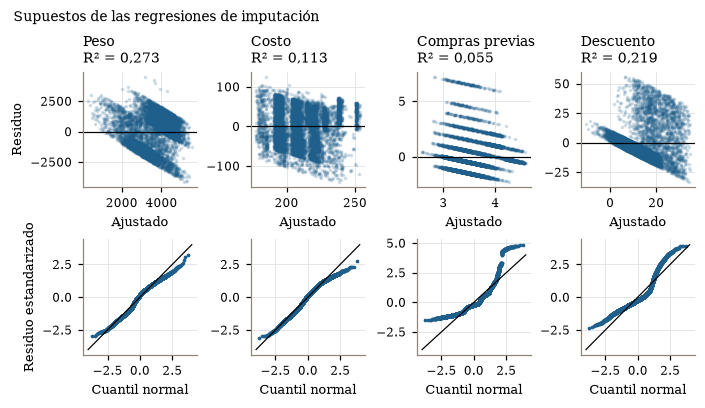

In [12]:
# Diagnóstico gráfico de los supuestos: residuos frente a ajustados (linealidad y homocedasticidad) y QQ (normalidad)
fig, axes = plt.subplots(2, len(VARS_FALTANTES), figsize=(ANCHO, 3.6))
for k, v in enumerate(VARS_FALTANTES):
    m = MODELOS_IMP[v]
    ax = axes[0, k]
    ax.scatter(m.fittedvalues, m.resid, s=2, alpha=0.15, color=AZUL, rasterized=True)
    ax.axhline(0, color='black', lw=0.8)
    ax.set_title(f'{ETIQ[v]}\nR² = {num(m.rsquared, 3)}')
    ax.set_xlabel('Ajustado')
    ax = axes[1, k]
    (osm, osr), _ = stats.probplot(m.resid / m.resid.std(ddof=1), dist='norm')
    ax.scatter(osm, osr, s=2, color=AZUL, rasterized=True)
    ax.plot([-4, 4], [-4, 4], color='black', lw=0.8)
    ax.set_xlabel('Cuantil normal')
axes[0, 0].set_ylabel('Residuo')
axes[1, 0].set_ylabel('Residuo estandarizado')
fig.suptitle('Supuestos de las regresiones de imputación', x=0.01, ha='left', fontsize=9)
guardar('fig_2_2_supuestos_imputacion', fig)

In [13]:
# Imputación: cada variable se predice con su modelo. Si un predictor también falta en esa fila,
# se completa provisionalmente con su mediana observada. Las predicciones se recortan al rango
# observado y se redondean, porque las cuatro variables son enteras en los datos originales.
mediana_obs = df_faltantes[VARS_FALTANTES].median()
df_regresion = df_faltantes.copy()
imputados = {}
for v in VARS_FALTANTES:
    faltan = df_faltantes[v].isna()
    X = df_faltantes.loc[faltan, PREDICTORES[v]]
    pred = MODELOS_IMP[v].predict(sm.add_constant(X.fillna(mediana_obs), has_constant='add'))
    minimo, maximo = df_faltantes[v].min(), df_faltantes[v].max()
    df_regresion.loc[faltan, v] = pred.clip(minimo, maximo).round()
    imputados[v] = {'imputados': int(faltan.sum()),
                    'con_predictor_provisional': int(X.isna().any(axis=1).sum()),
                    'recortados_al_rango': int(((pred < minimo) | (pred > maximo)).sum())}
df_regresion[VARS_FALTANTES] = df_regresion[VARS_FALTANTES].astype(df[VARS_FALTANTES].dtypes.to_dict())
assert df_regresion.notna().all().all() and df_regresion.index.equals(df.index)
assert df_regresion.where(~df_faltantes.isna()).equals(df.where(~df_faltantes.isna())), 'Lo observado no cambia.'

conteo_imputados = pd.DataFrame(imputados).T
conteo_imputados.to_csv(TABLAS / 'imputacion_conteo.csv')
print(f'Valores imputados por regresión: {num(conteo_imputados["imputados"].sum())} en total')
display(conteo_imputados)

Valores imputados por regresión: 4.360 en total


,imputados,con_predictor_provisional,recortados_al_rango
peso_gramos,1086,272,5
costo_producto,1107,189,0
compras_previas,1055,191,0
descuento_ofrecido,1112,282,24


**Resultado.**

- **Capacidad predictiva modesta, como anticipaba S1 (|ρ| ≤ 0,32):**
  - R² de validación cruzada de 0,27 en peso, 0,22 en descuento, 0,11 en costo y 0,05 en compras previas;
  - el RMSE equivale al 85–97 % de la desviación estándar de cada variable, así que la regresión mejora poco frente a imputar un valor constante;
  - el R² de validación cruzada casi coincide con el de ajuste, así que no hay sobreajuste;
  - todos los coeficientes son significativos y tienen el signo de la ρ de S1.
- **Supuestos:**
  - normalidad: Jarque-Bera rechaza en las cuatro variables, porque son discretas y acotadas;
  - homocedasticidad: Breusch-Pagan también rechaza;
  - con n > 7.000, ambas violaciones afectan a los errores estándar, no a la predicción puntual, que es lo único que usa la imputación;
  - independencia: Durbin-Watson muestra autocorrelación en peso (1,01) y descuento (1,33). Es coherente con el orden del archivo detectado en S2 y tampoco sesga la predicción;
  - multicolinealidad: no hay (VIF máximo 1,21).
- **Valores imputados:** 4.360 en total (1.086 en peso, 1.107 en costo, 1.055 en compras previas y 1.112 en descuento).
  - Entre 189 y 282 por variable usaron un predictor completado provisionalmente con su mediana.
  - Se recortaron al rango observado 5 predicciones de peso y 24 de descuento.
  - Los valores observados no se modifican.
- **Para 2.3:** una regresión con R² bajo predice valores cercanos a la media y **reduce la variabilidad** de lo imputado. Esto se evalúa al comparar las distribuciones con las otras estrategias.

### 2.3 Comparación de estrategias y decisión

Se comparan tres formas de tratar los faltantes:

1. **eliminación** de las filas con algún faltante (análisis de casos completos);
2. **imputación simple por la mediana** observada, que es robusta a la asimetría y a los extremos válidos que S1 decidió conservar;
3. **imputación por regresión** (2.2).

Cada estrategia produce un dataset sin faltantes que conserva el índice original de los envíos. Los tres se usan de nuevo en la Parte 3.

**Criterios:**

- (a) *n* resultante y tamaño de la partición común;
- (b) distribución de cada variable frente a los datos originales: media, DE, cuartiles y prueba de Kolmogorov-Smirnov (KS);
- (c) preservación de las correlaciones de Spearman de S1, entre numéricas y con el atraso;
- (d) error de los valores imputados frente a los **valores reales**. Esta evidencia solo existe porque los faltantes son simulados;
- (e) **asignación al segmento de descuento** que S1 identificó: los envíos con descuento > 10 están 100 % atrasados. Se cuentan los envíos que, con el descuento imputado, quedan al otro lado del umbral respecto de su valor real. Este criterio importa porque la Parte 2 modela por segmento, siguiendo la recomendación de la Formativa 2.

In [14]:
# 2.3 Las tres estrategias, como DataFrames sin NaN que conservan el índice original de los envíos
mediana_entera = df_faltantes[VARS_FALTANTES].median().round()   # valores enteros, como los datos originales
DATASETS = {
    'eliminacion': df_faltantes.dropna().astype(df.dtypes.to_dict()),
    'mediana': df_faltantes.fillna(mediana_entera).astype(df.dtypes.to_dict()),
    'regresion': df_regresion,
}
for k, d in DATASETS.items():
    assert d.notna().all().all() and d.index.isin(df.index).all() and list(d.columns) == list(df.columns), k

# (a) Tamaño resultante, partición común y tasa de atraso
filas = []
for k, d in DATASETS.items():
    tr, te = particionar(d)
    filas.append({'estrategia': k, 'n': len(d), 'pct_conservado': len(d) / len(df) * 100,
                  'n_entrenamiento': len(tr), 'n_prueba': len(te), 'tasa_atraso': d[TARGET].mean() * 100})
comparacion_n = pd.DataFrame(filas).set_index('estrategia')
comparacion_n.loc['original'] = [len(df), 100.0, len(IDX_TRAIN), len(IDX_TEST), df[TARGET].mean() * 100]
comparacion_n.to_csv(TABLAS / 'estrategias_tamano.csv')
print('Tamaño de cada dataset:')
display(comparacion_n.round(2))

Tamaño de cada dataset:


,n,pct_conservado,n_entrenamiento,n_prueba,tasa_atraso
estrategia,,,,,
eliminacion,7213.0,65.58,5058.0,2155.0,59.66
mediana,10999.0,100.00,7699.0,3300.0,59.67
regresion,10999.0,100.00,7699.0,3300.0,59.67
original,10999.0,100.00,7699.0,3300.0,59.67


In [15]:
# (b) Distribución de cada variable frente a los datos originales (media, DE, cuartiles y prueba KS)
filas = []
for v in VARS_FALTANTES:
    for k, d in [('original', df)] + list(DATASETS.items()):
        x = d[v]
        ks = stats.ks_2samp(x, df[v]) if k != 'original' else None
        filas.append({'variable': v, 'estrategia': k, 'media': x.mean(), 'de': x.std(ddof=1),
                      'q25': x.quantile(0.25), 'q50': x.median(), 'q75': x.quantile(0.75),
                      'ks_d': ks.statistic if ks else np.nan, 'ks_p': ks.pvalue if ks else np.nan})
comparacion_dist = pd.DataFrame(filas).set_index(['variable', 'estrategia'])
comparacion_dist['de_relativa'] = comparacion_dist['de'] / comparacion_dist.xs('original', level=1)['de'].reindex(
    comparacion_dist.index, level=0)
comparacion_dist.to_csv(TABLAS / 'estrategias_distribuciones.csv')
print('Distribuciones (de_relativa = DE del dataset / DE original):')
display(comparacion_dist.round(3))

# (c) Preservación de las correlaciones de Spearman de S1: entre numéricas y con el atraso
triangulo = np.triu(np.ones((len(CANDIDATAS), len(CANDIDATAS)), dtype=bool), k=1)
ref_pares = spearman_s1.loc[CANDIDATAS, CANDIDATAS].to_numpy()[triangulo]
ref_atraso = atraso.loc[VARS_FALTANTES, 'rho_s1']
filas, detalle = [], []
for k, d in DATASETS.items():
    pares_k = d[CANDIDATAS].corr(method='spearman').to_numpy()[triangulo]
    atraso_k = d[VARS_FALTANTES].corrwith(d[TARGET], method='spearman')
    dif = np.abs(pares_k - ref_pares)
    filas.append({'estrategia': k, 'dif_max_pares': dif.max(), 'dif_media_pares': dif.mean(),
                  'dif_max_atraso': (atraso_k - ref_atraso).abs().max()})
    detalle.append(pd.DataFrame({'estrategia': k, 'variable': VARS_FALTANTES, 'rho_atraso_s1': ref_atraso.to_numpy(),
                                 'rho_atraso': atraso_k.to_numpy()}))
comparacion_cor = pd.DataFrame(filas).set_index('estrategia')
cor_atraso_estrategias = pd.concat(detalle).set_index(['variable', 'estrategia']).sort_index()
comparacion_cor.to_csv(TABLAS / 'estrategias_correlaciones.csv')
cor_atraso_estrategias.to_csv(TABLAS / 'estrategias_correlacion_atraso.csv')
print('Diferencia absoluta con las ρ de Spearman de S1 (10 pares de numéricas y 4 correlaciones con el atraso):')
display(comparacion_cor.round(4))
print('ρ de Spearman con el atraso, por estrategia:')
display(cor_atraso_estrategias.round(4))

# (d) Error frente al valor real (solo posible porque los faltantes son simulados)
filas = []
for k in ['mediana', 'regresion']:
    for v in VARS_FALTANTES:
        real, imp = df.loc[MASCARA[v], v], DATASETS[k].loc[MASCARA[v], v]
        filas.append({'variable': v, 'estrategia': k, 'rmse': np.sqrt(((imp - real) ** 2).mean()),
                      'mae': (imp - real).abs().mean(), 'de_imputados': imp.std(ddof=1), 'de_reales': real.std(ddof=1)})
error_real = pd.DataFrame(filas).set_index(['variable', 'estrategia'])
error_real['rmse_relativo'] = error_real['rmse'] / error_real['de_reales']
error_real.to_csv(TABLAS / 'estrategias_error_valor_real.csv')
print('Error de los valores imputados frente a los reales:')
display(error_real.round(3))

Distribuciones (de_relativa = DE del dataset / DE original):


media        de     q25     q50     q75  \
variable           estrategia                                                
peso_gramos        original     3634.017  1635.377  1839.5  4149.0  5050.0   
                   eliminacion  3625.825  1636.555  1837.0  4142.0  5043.0   
                   mediana      3674.934  1561.446  1923.0  4139.0  4940.0   
                   regresion    3627.043  1575.873  1909.0  4080.0  4947.5   
costo_producto     original      210.197    48.063   169.0   214.0   251.0   
                   eliminacion   210.053    48.199   169.0   214.0   251.0   
                   mediana       210.523    45.489   175.0   214.0   247.0   
                   regresion     210.078    45.749   175.0   211.0   247.0   
compras_previas    original        3.568     1.523     3.0     3.0     4.0   
                   eliminacion     3.566     1.513     3.0     3.0     4.0   
                   mediana         3.510     1.460     3.0     3.0     4.0   
                   regresion       3.560     1.460     3.0     3.0     4.0   
descuento_ofrecido original       13.373    16.206     4.0     7.0    10.0   
                   eliminacion    13.303    16.098     4.0     7.0    10.0   
                   mediana        12.707    15.488     4.0     7.0    10.0   
                   regresion      13.328    15.540     4.0     7.0    13.0   

                                 ks_d   ks_p  de_relativa  
variable           estrategia                              
peso_gramos        original       NaN    NaN        1.000  
                   eliminacion  0.005  1.000        1.001  
                   mediana      0.053  0.000        0.955  
                   regresion    0.030  0.000        0.964  
costo_producto     original       NaN    NaN        1.000  
                   eliminacion  0.004  1.000        1.003  
                   mediana      0.051  0.000        0.946  
                   regresion    0.033  0.000        0.952  
compras_previas    original       NaN    NaN        1.000  
                   eliminacion  0.003  1.000        0.994  
                   mediana      0.040  0.000        0.959  
                   regresion    0.021  0.017        0.958  
descuento_ofrecido original       NaN    NaN        1.000  
                   eliminacion  0.004  1.000        0.993  
                   mediana      0.048  0.000        0.956  
                   regresion    0.037  0.000        0.959

Diferencia absoluta con las ρ de Spearman de S1 (10 pares de numéricas y 4 correlaciones con el atraso):


,dif_max_pares,dif_media_pares,dif_max_atraso
estrategia,,,
eliminacion,0.0121,0.0071,0.0058
mediana,0.0265,0.0120,0.0226
regresion,0.0431,0.0188,0.0124


ρ de Spearman con el atraso, por estrategia:


rho_atraso_s1  rho_atraso
variable           estrategia                            
compras_previas    eliminacion        -0.0746     -0.0785
                   mediana            -0.0746     -0.0700
                   regresion          -0.0746     -0.0623
costo_producto     eliminacion        -0.0719     -0.0725
                   mediana            -0.0719     -0.0703
                   regresion          -0.0719     -0.0712
descuento_ofrecido eliminacion         0.3351      0.3409
                   mediana             0.3351      0.3126
                   regresion           0.3351      0.3330
peso_gramos        eliminacion        -0.2660     -0.2663
                   mediana            -0.2660     -0.2666
                   regresion          -0.2660     -0.2649

Error de los valores imputados frente a los reales:


,,rmse,mae,de_imputados,de_reales,rmse_relativo
variable,estrategia,,,,,
peso_gramos,mediana,1671.843,1391.106,0.000,1620.413,1.032
costo_producto,mediana,49.154,42.351,0.000,49.069,1.002
compras_previas,mediana,1.609,1.036,0.000,1.493,1.078
descuento_ofrecido,mediana,17.448,9.604,0.000,16.163,1.080
peso_gramos,regresion,1382.127,1155.645,834.961,1620.413,0.853
costo_producto,regresion,46.984,40.066,15.768,49.069,0.958
compras_previas,regresion,1.479,0.984,0.511,1.493,0.991
descuento_ofrecido,regresion,14.271,10.048,7.222,16.163,0.883


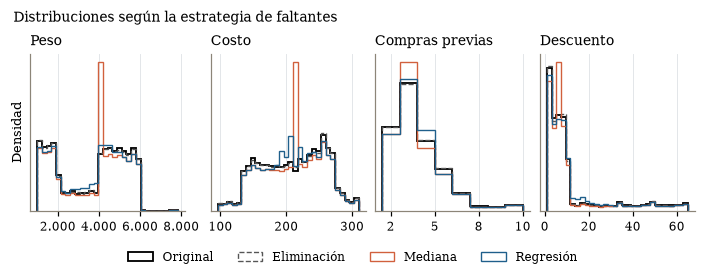

In [16]:
# Figura: distribución de cada variable según la estrategia, frente a los datos originales
fig, axes = plt.subplots(1, len(VARS_FALTANTES), figsize=(ANCHO, 2.4))
estilos = {'original': dict(color='black', lw=1.2), 'eliminacion': dict(color=GRIS, lw=0.9, ls='--'),
           'mediana': dict(color=TERRA, lw=0.9), 'regresion': dict(color=AZUL, lw=0.9)}
nombres = {'original': 'Original', 'eliminacion': 'Eliminación', 'mediana': 'Mediana', 'regresion': 'Regresión'}
for ax, v in zip(axes, VARS_FALTANTES):
    bordes = np.histogram_bin_edges(df[v], bins=min(30, df[v].nunique()))
    for k, d in [('original', df)] + list(DATASETS.items()):
        ax.hist(d[v], bins=bordes, density=True, histtype='step', label=nombres[k], **estilos[k])
    ax.set_title(ETIQ[v])
    ax.set_yticks([])
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: num(x)))
axes[0].set_ylabel('Densidad')
fig.legend(*axes[0].get_legend_handles_labels(), loc='outside lower center', ncol=4)
fig.suptitle('Distribuciones según la estrategia de faltantes', x=0.01, ha='left', fontsize=9)
guardar('fig_2_3_distribuciones_estrategias', fig)

In [17]:
# Síntesis de los criterios por estrategia y decisión
resumen_estrategias = pd.DataFrame({
    'n': comparacion_n['n'],
    'ks_d_medio': comparacion_dist['ks_d'].groupby(level='estrategia').mean(),
    'de_relativa_media': comparacion_dist['de_relativa'].groupby(level='estrategia').mean(),
    'dif_max_pares_s1': comparacion_cor['dif_max_pares'],
    'dif_max_atraso_s1': comparacion_cor['dif_max_atraso'],
    'rmse_relativo_medio': error_real['rmse_relativo'].groupby(level='estrategia').mean(),
}).loc[list(DATASETS)]
# (e) Asignación al segmento de descuento de S1 (> 10, 100 % atrasado) frente al valor real del descuento
for k, d in DATASETS.items():
    real_alto, asignado_alto = df.loc[d.index, 'descuento_ofrecido'] > 10, d['descuento_ofrecido'] > 10
    resumen_estrategias.loc[k, 'real_le10_asignado_mayor10'] = int((asignado_alto & ~real_alto).sum())
    resumen_estrategias.loc[k, 'real_mayor10_asignado_le10'] = int((~asignado_alto & real_alto).sum())
    resumen_estrategias.loc[k, 'atraso_segmento_mayor10'] = d.loc[asignado_alto, TARGET].mean()
resumen_estrategias.to_csv(TABLAS / 'estrategias_resumen.csv')
display(resumen_estrategias.round(4))

ESTRATEGIA = 'regresion'   # decisión justificada en la celda siguiente
assert ESTRATEGIA in DATASETS

# Exporta los tres datasets (y los faltantes simulados) para la Parte 3 y para la trazabilidad
DATOS_S3 = RAIZ / 'outputs/datos'
DATOS_S3.mkdir(parents=True, exist_ok=True)
df_faltantes.to_csv(DATOS_S3 / 'dataset_faltantes_mar.csv', index_label='indice')
for k, d in DATASETS.items():
    d.to_csv(DATOS_S3 / f'dataset_{k}.csv', index_label='indice')
print(f'Estrategia elegida: {ESTRATEGIA} | datasets exportados en {DATOS_S3.relative_to(REPO).as_posix()}/')

,n,ks_d_medio,de_relativa_media,dif_max_pares_s1,dif_max_atraso_s1,rmse_relativo_medio,real_le10_asignado_mayor10,real_mayor10_asignado_le10,atraso_segmento_mayor10
estrategia,,,,,,,,,
eliminacion,7213.0,0.0040,0.9976,0.0121,0.0058,NaN,0.0,0.0,1.000
mediana,10999.0,0.0480,0.9540,0.0265,0.0226,1.0477,0.0,268.0,1.000
regresion,10999.0,0.0303,0.9582,0.0431,0.0124,0.9211,428.0,19.0,0.926


Estrategia elegida: regresion | datasets exportados en sumativa_3/outputs/datos/


**Comparación y decisión.**

| Criterio | Eliminación | Mediana | Regresión |
|---|---|---|---|
| (a) *n* (entrenamiento / prueba) | 7.213 (5.058 / 2.155) | 10.999 (7.699 / 3.300) | 10.999 (7.699 / 3.300) |
| (b) KS medio frente al original | **0,004** | 0,048 | 0,030 |
| (b) DE relativa media | **1,00** | 0,95 | 0,96 |
| (c) Máx. \|Δρ\| entre numéricas (S1) | **0,012** | 0,027 | 0,043 |
| (c) Máx. \|Δρ\| con el atraso (S1) | **0,006** | 0,023 | 0,012 |
| (d) RMSE / DE frente al valor real | — | 1,05 | **0,92** |
| (e) Real ≤ 10 asignado a > 10 / real > 10 asignado a ≤ 10 | **0 / 0** | 0 / 268 | 428 / 19 |
| (e) Atraso en el segmento > 10 (S1: 100 %) | **100 %** | **100 %** | 92,6 % |

- **Eliminación:**
  - conserva las distribuciones, las correlaciones de S1 y los segmentos de descuento casi sin cambios. Esto ocurre porque las variables que generan los faltantes (importancia, bodega, modalidad y género) se relacionan poco con las numéricas;
  - a cambio, **pierde el 34,4 % de los envíos**: el entrenamiento baja de 7.699 a 5.058, lo que ensancha los IC y resta potencia a la Parte 2;
  - además, bajo un mecanismo MAR más fuerte, la eliminación podría sesgar los resultados.
- **Mediana:**
  - es la peor en casi todos los criterios: crea un pico artificial en la mediana, desplaza la media del descuento (12,7 frente a 13,4) y reduce la DE;
  - **atenúa la correlación del descuento con el atraso** (0,313 frente a 0,335), que es el predictor más fuerte de S1;
  - su error frente al valor real supera la DE de cada variable;
  - como imputa el descuento con 7, **lleva al segmento ≤ 10 a 268 envíos con descuento real > 10, todos atrasados**, y contamina el segmento que modela la Parte 2.
- **Regresión:**
  - conserva el *n* completo y la partición común de la Formativa 2;
  - tiene el **menor error frente al valor real**;
  - conserva las medias y la relación con el atraso de los dos predictores principales de S1: descuento (0,333 frente a 0,335, mientras la mediana la baja a 0,313) y peso (−0,265 frente a −0,266). Atenúa la de compras previas (−0,062 frente a −0,075), que S2 ya calificó como débil y sensible;
  - su costo es el defecto conocido de la regresión determinista: reduce la variabilidad (DE ≈ 96 %) y **acentúa la correlación peso–descuento** (de −0,316 a −0,359), porque los valores imputados caen sobre la recta de regresión;
  - además, **desplaza envíos entre segmentos de descuento**. Imputa descuentos con mediana 12,5, cerca de la media del descuento (13,4) y sobre el umbral de 10. Por eso **428 envíos con descuento real ≤ 10 quedan en el segmento > 10**, cuya tasa de atraso baja de 100 % a 92,6 %. Es el efecto de imputar con un valor continuo una variable cuyo efecto es de umbral.

**Decisión: imputación por regresión** (`ESTRATEGIA = 'regresion'`), para el resto de la evaluación. Es la estrategia que conserva toda la muestra y predice mejor los valores reales, y deja intacta la relación del peso y el descuento con el atraso, que S1 y S2 identificaron como las asociaciones principales.

Se adopta **con una limitación explícita**: la asignación al segmento de descuento, que la Parte 2 usa para separar el modelo de la regla. La eliminación queda como **referencia de sensibilidad**. La Parte 3 verifica que, con el modelo final por segmento, la regresión es la estrategia que mejor reproduce el coeficiente obtenido con los datos originales, y cuantifica cuánto le cuesta al clasificador combinado la mala asignación del segmento.

## 3. Parte 2: clasificación mediante regresión logística

**Responsable:** Sebastián (3.1–3.3 y 3.5) y Yerko (3.4) · **Revisor:** Yerko y José

**Rúbrica (30 + 30 pts):** tres modelos con selección informada por S1 y S2; interpretación rigurosa de coeficientes y odds ratios; decisión final fundamentada. *Bootstrap* del modelo final con IC de coeficientes y OR, parámetros inestables y comparación con los IC tradicionales.

**Recomendaciones de la retroalimentación de la Formativa 2 (F2) aplicadas en esta parte:**
1. Los tres modelos se ajustan en el **segmento con descuento ≤ 10**. El segmento > 10 se clasifica con una regla, porque su atraso es del 100 % (S1), y un indicador produciría separación completa.
2. Los tres modelos son: **variables actuales** (las de F2), ***stepwise* por AIC** y **reducido** (mínimo BIC).
3. El desempeño se compara con el AUC de **0,714** de F2 y, sobre todo, con el **0,521** de su segmento ≤ 10.
4. Se aplica *bootstrap* a los coeficientes del modelo final para ver **cuáles conservan su signo**.
5. No se ponderan las clases: dentro del segmento están casi equilibradas (47 % de atraso), y ponderar solo mueve el equilibrio entre recall y especificidad.

Quedan fuera las técnicas que no corresponden al curso: RFE, penalización, validación cruzada anidada y calibración.

**Contenido:**
- **3.1** Preparación: `DATASETS[ESTRATEGIA]`, partición común, segmentación por el descuento, outliers y `disenar()`.
- **3.2** M1 (variables actuales), M2 (*stepwise* por AIC) y M3 (reducido por BIC), en el segmento ≤ 10.
- **3.3** Matrices de confusión en entrenamiento y prueba, métricas y ROC/AUC: en el segmento y en el clasificador combinado (modelo para ≤ 10 y regla para > 10). Comparación con F2 y selección del modelo final.
- **3.4** *Bootstrap* (B = 10.000) de los coeficientes de los tres modelos, con énfasis en el final: IC percentil y BCa frente a los de Wald y conservación del signo.
- **3.5** Diagnóstico: VIF, linealidad en el logit, observaciones influyentes y residuos.

**Contrato:**
- `MODELOS = {'M1', 'M2', 'M3'}`, cada uno con sus `numericas` y `categoricas`;
- `MODELO_FINAL`;
- `UMBRAL_SEGMENTO = 10`.

### 3.1 Preparación y trazabilidad

Se usa `DATASETS[ESTRATEGIA]` con la partición común 70/30. Se conservan los extremos válidos (S1, `calidad_datos.csv`; S2, sensibilidad a la winsorización). La estandarización usa solo el entrenamiento del segmento, y las categorías se codifican con referencia al primer nivel ordenado.

**Segmentación por el descuento (recomendación de F2).**

- **Por qué se separa el segmento > 10.** S1 mostró que los 2.647 envíos con descuento > 10 están **todos** atrasados (IC de Wilson [0,9986; 1]). S2 encontró que la asociación del descuento con el atraso existe solo por ese segmento. La F2 mostró que, fuera de él, su modelo discriminaba como el azar (AUC 0,521).
- **Por qué no se usa un indicador.** Incluir un indicador "descuento > 10" produciría separación completa: su coeficiente de máxima verosimilitud no existe.
- **Diseño adoptado:**
  - los **tres modelos se ajustan en el segmento ≤ 10**, donde está la incertidumbre real;
  - el segmento > 10 se clasifica con una **regla**: probabilidad igual a la tasa de atraso observada en ese segmento del entrenamiento;
  - el **clasificador combinado** (modelo + regla) se evalúa sobre todos los envíos, para compararlo con F2.
- **Limitación por la imputación.** El segmento se asigna con el descuento del dataset elegido. Con la imputación por regresión, algunos descuentos faltantes quedan sobre 10 aunque su valor real era ≤ 10; la Parte 3 cuantifica ese efecto.

**Variables.** M1 conserva peso, descuento, costo y compras previas, por continuidad con F2. **Solo el peso fue robusto en todos los escenarios de S2.** M2 y M3 consideran además importancia, bodega, modalidad y género. Se excluyen el ID, por la estructura del archivo, y llamadas y calificación, porque pueden registrarse después de la entrega (limitaciones de S1 y *jackknife* de S2).

**Ponderación de clases.** No se aplica: en el segmento ≤ 10 el atraso es cercano al 47 %, y ponderar las clases solo desplaza el equilibrio entre recall y especificidad, como cambiar el umbral (F2).

**Alcance de la evaluación.** La Parte 1 ajusta imputaciones y medianas sobre toda la base. Aunque no usa el atraso, incorpora información de los predictores de prueba. Por ello, los resultados principales describen el dataset acordado y se complementan con una sensibilidad que ajusta la imputación solo con el entrenamiento.

In [18]:
from itertools import combinations
from sklearn.metrics import roc_curve
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.outliers_influence import variance_inflation_factor

NUM_S3 = ['peso_gramos', 'descuento_ofrecido', 'costo_producto', 'compras_previas']
CAT_S3 = ['importancia_producto', 'bloque_bodega', 'modalidad_envio', 'genero']
CAND_S3 = NUM_S3 + CAT_S3
UMBRAL_SEGMENTO = 10   # S1: con descuento > 10, los 2.647 envíos están atrasados (IC de Wilson [0,9986; 1])


def en_segmento(datos):
    # Segmento modelado: descuento <= 10 (valor del dataset; en los faltantes, el imputado)
    return datos['descuento_ofrecido'] <= UMBRAL_SEGMENTO


train_total_s3, test_total_s3 = particionar(DATASETS[ESTRATEGIA])
train_s3, test_s3 = train_total_s3[en_segmento(train_total_s3)], test_total_s3[en_segmento(test_total_s3)]
alto_train_s3, alto_test_s3 = train_total_s3[~en_segmento(train_total_s3)], test_total_s3[~en_segmento(test_total_s3)]
P_ALTO_S3 = alto_train_s3[TARGET].mean()   # regla del segmento > 10: tasa observada en entrenamiento
X_train_s3 = disenar(train_s3, NUM_S3, CAT_S3, train_s3)
X_test_s3 = disenar(test_s3, NUM_S3, CAT_S3, train_s3)
y_train_s3, y_test_s3 = train_s3[TARGET], test_s3[TARGET]
BLOQUES_S3 = {v: [v] if v in NUM_S3 else [c for c in X_train_s3 if c.startswith(v + '_')] for v in CAND_S3}
assert X_train_s3.columns.equals(X_test_s3.columns)
assert train_s3.index.intersection(test_s3.index).empty
segmentos_s3 = pd.DataFrame([{'conjunto': c, 'segmento': s, 'envios': len(d), 'tasa_atraso': d[TARGET].mean()}
                             for c, b, a in [('entrenamiento', train_s3, alto_train_s3), ('prueba', test_s3, alto_test_s3)]
                             for s, d in [('descuento <= 10 (modelo)', b), ('descuento > 10 (regla)', a)]])
segmentos_s3.to_csv(TABLAS / 'modelos_segmentos.csv', index=False)
preparacion_s3 = pd.DataFrame({'media': train_s3[NUM_S3].mean(), 'de': train_s3[NUM_S3].std(ddof=1)})
preparacion_s3.to_csv(TABLAS / 'modelos_preparacion.csv')
pd.DataFrame([{'variable': v, 'referencia': NIVELES[v][0], 'niveles': ', '.join(NIVELES[v])} for v in CAT_S3]).to_csv(TABLAS / 'modelos_categorias.csv', index=False)
UNIDADES_S3 = {'peso_gramos': (1000, '1.000 g'), 'descuento_ofrecido': (1, '1 unidad'),
               'costo_producto': (10, '10 USD'), 'compras_previas': (1, '1 compra')}
ESCALAS_S3 = {v: (u, preparacion_s3.loc[v, 'de'], etiqueta) for v, (u, etiqueta) in UNIDADES_S3.items()}
CACHE_S3 = {}
def columnas_s3(variables):
    return [c for v in CAND_S3 if v in variables for c in BLOQUES_S3[v]]
def fit_s3(variables):
    clave = tuple(v for v in CAND_S3 if v in variables)
    if clave not in CACHE_S3:
        CACHE_S3[clave] = ajustar_logit(X_train_s3[columnas_s3(clave)], y_train_s3)
    return CACHE_S3[clave]
def p_lr_s3(completo, reducido):
    return stats.chi2.sf(max(0., 2 * (completo.llf - reducido.llf)), int(completo.df_model - reducido.df_model))
display(segmentos_s3.round(4))
display(preparacion_s3.round(4))

,conjunto,segmento,envios,tasa_atraso
0,entrenamiento,descuento <= 10 (modelo),5572,0.4711
1,entrenamiento,descuento > 10 (regla),2127,0.9257
2,prueba,descuento <= 10 (modelo),2371,0.4673
3,prueba,descuento > 10 (regla),929,0.9268


,media,de
peso_gramos,4062.5373,1527.0507
descuento_ofrecido,5.5332,2.9006
costo_producto,214.4257,45.8087
compras_previas,3.6346,1.4545


### 3.2 Tres modelos en el segmento ≤ 10: variables actuales, *stepwise* por AIC y reducido

- **M1 (variables actuales):** peso, descuento, costo y compras previas, las de F2, elegidas por sus correlaciones de S1 validadas en S2. Dentro del segmento, el descuento varía solo entre 1 y 10; por eso su OR se expresa **por unidad**.
- **M2 (*stepwise* por AIC):** selección bidireccional desde el intercepto. En cada paso evalúa agregar o quitar cada variable y aplica el cambio que más reduce el AIC; se detiene cuando ningún cambio lo reduce. Las categóricas entran y salen completas, y se registra cada movimiento.
- **M3 (reducido):** el subconjunto de mínimo BIC entre los 256 posibles de las ocho variables, por búsqueda exhaustiva. Como el BIC penaliza más que el AIC con *n* grande, favorece el modelo más parsimonioso.

Todos se ajustan solo con el entrenamiento del segmento. Los IC de Wald y los valores *p* posteriores a la selección son **condicionales a la especificación elegida**: no incorporan la incertidumbre de selección ni la de imputación, y la sección 3.4 la evalúa con *bootstrap*. Un OR multiplica las *odds*, no la probabilidad, y no demuestra causalidad.

In [19]:
# M2: stepwise bidireccional por AIC, desde el intercepto (en cada paso, el mejor movimiento de entrada o salida)
seleccionadas, pasos_s3 = [], []
aic_actual = fit_s3([]).aic
while True:
    movimientos = []
    for v in CAND_S3:
        nuevo = [w for w in seleccionadas if w != v] if v in seleccionadas else seleccionadas + [v]
        movimientos.append((fit_s3(nuevo).aic, 'salida' if v in seleccionadas else 'entrada', v, nuevo))
    aic_nuevo, accion, v, nuevo = min(movimientos, key=lambda m: m[0])
    if aic_nuevo >= aic_actual - 1e-9:
        break
    pasos_s3.append({'paso': len(pasos_s3) + 1, 'accion': accion, 'variable': v, 'aic_previo': aic_actual, 'aic': aic_nuevo})
    seleccionadas, aic_actual = nuevo, aic_nuevo
    assert len(pasos_s3) < 50, 'El stepwise no converge.'
pd.DataFrame(pasos_s3).to_csv(TABLAS / 'modelos_stepwise.csv', index=False)

# M3: mejor subconjunto por BIC (búsqueda exhaustiva de los 256 subconjuntos)
subconjuntos = []
for k in range(len(CAND_S3) + 1):
    for vs in combinations(CAND_S3, k):
        m = fit_s3(vs)
        subconjuntos.append({'variables': '|'.join(vs), 'n_variables': k, 'n_parametros': len(m.params),
                             'aic': m.aic, 'bic': m.bic, 'loglik': m.llf})
busqueda_s3 = pd.DataFrame(subconjuntos).sort_values(['bic', 'n_parametros', 'variables']).reset_index(drop=True)
assert len(busqueda_s3) == 256
busqueda_s3.to_csv(TABLAS / 'modelos_busqueda_bic.csv', index=False)
mejores_bic = busqueda_s3.iloc[0]['variables'].split('|') if busqueda_s3.iloc[0]['variables'] else []
MODELOS = {k: {'numericas': [v for v in NUM_S3 if v in vs], 'categoricas': [v for v in CAT_S3 if v in vs]}
           for k, vs in {'M1': NUM_S3, 'M2': seleccionadas, 'M3': mejores_bic}.items()}
NOMBRE_MODELO = {'M1': 'M1 · variables actuales', 'M2': 'M2 · stepwise AIC', 'M3': 'M3 · reducido (BIC)'}
AJUSTES_S3 = {k: fit_s3(spec['numericas'] + spec['categoricas']) for k, spec in MODELOS.items()}
coeficientes_s3 = pd.concat({k: tabla_odds_ratios(m, ESCALAS_S3) for k, m in AJUSTES_S3.items()}, names=['modelo', 'predictor'])
coeficientes_s3.to_csv(TABLAS / 'modelos_coeficientes_or.csv')
resumen_modelos_s3 = pd.DataFrame([{'modelo': k, 'variables': ', '.join(MODELOS[k]['numericas'] + MODELOS[k]['categoricas']),
                                   'n': int(m.nobs), 'n_parametros': len(m.params), 'aic': m.aic, 'bic': m.bic,
                                   'intercepto': m.params['const'], 'convergio': m.mle_retvals['converged']}
                                  for k, m in AJUSTES_S3.items()]).set_index('modelo')
resumen_modelos_s3.to_csv(TABLAS / 'modelos_resumen.csv')
display(pd.DataFrame(pasos_s3))
display(resumen_modelos_s3)
display(coeficientes_s3.round(4))

,paso,accion,variable,aic_previo,aic
0,1,entrada,peso_gramos,7707.813769,7677.275948
1,2,entrada,compras_previas,7677.275948,7671.328897
2,3,entrada,importancia_producto,7671.328897,7665.335625
3,4,entrada,costo_producto,7665.335625,7663.622349


,variables,n,n_parametros,aic,bic,intercepto,convergio
modelo,,,,,,,
M1,"peso_gramos, descuento_ofrecido, costo_product...",5572,5,7671.043139,7704.170686,-0.116533,True
M2,"peso_gramos, costo_producto, compras_previas, ...",5572,6,7663.622349,7703.375405,0.143817,True
M3,peso_gramos,5572,2,7677.275948,7690.526967,-0.116151,True


coef      ee       z       p  ic_inf  \
modelo predictor                                                             
M1     peso_gramos                 -0.1969  0.0302 -6.5147  0.0000 -0.2562   
       descuento_ofrecido          -0.0228  0.0270 -0.8467  0.3972 -0.0757   
       costo_producto              -0.0551  0.0293 -1.8838  0.0596 -0.1124   
       compras_previas             -0.0772  0.0285 -2.7084  0.0068 -0.1331   
M2     peso_gramos                 -0.2031  0.0305 -6.6667  0.0000 -0.2629   
       costo_producto              -0.0564  0.0293 -1.9260  0.0541 -0.1138   
       compras_previas             -0.0800  0.0286 -2.7992  0.0051 -0.1361   
       importancia_producto_low    -0.2505  0.1017 -2.4642  0.0137 -0.4498   
       importancia_producto_medium -0.3230  0.1023 -3.1584  0.0016 -0.5234   
M3     peso_gramos                 -0.1533  0.0269 -5.6921  0.0000 -0.2060   

                                    ic_sup      or  or_inf  or_sup  or_unidad  \
modelo predictor                                                                
M1     peso_gramos                 -0.1377  0.8213  0.7740  0.8714     0.8790   
       descuento_ofrecido           0.0300  0.9774  0.9271  1.0305     0.9922   
       costo_producto               0.0022  0.9464  0.8937  1.0022     0.9880   
       compras_previas             -0.0213  0.9257  0.8753  0.9789     0.9483   
M2     peso_gramos                 -0.1434  0.8162  0.7688  0.8664     0.8754   
       costo_producto               0.0010  0.9451  0.8924  1.0010     0.9878   
       compras_previas             -0.0240  0.9231  0.8728  0.9763     0.9465   
       importancia_producto_low    -0.0513  0.7784  0.6378  0.9500        NaN   
       importancia_producto_medium -0.1225  0.7240  0.5925  0.8847        NaN   
M3     peso_gramos                 -0.1005  0.8579  0.8138  0.9044     0.9045   

                                    or_unidad_inf  or_unidad_sup    unidad  
modelo predictor                                                            
M1     peso_gramos                         0.8456         0.9138   1.000 g  
       descuento_ofrecido                  0.9742         1.0104  1 unidad  
       costo_producto                      0.9758         1.0005    10 USD  
       compras_previas                     0.9125         0.9854  1 compra  
M2     peso_gramos                         0.8419         0.9104   1.000 g  
       costo_producto                      0.9755         1.0002    10 USD  
       compras_previas                     0.9107         0.9836  1 compra  
       importancia_producto_low               NaN            NaN       NaN  
       importancia_producto_medium            NaN            NaN       NaN  
M3     peso_gramos                         0.8738         0.9363   1.000 g

### 3.3 Desempeño y selección

Se reportan entrenamiento y prueba con umbral fijo 0,5. El desempeño se evalúa en dos niveles:

1. **En el segmento ≤ 10**, donde operan los modelos. La comparación clave es con el AUC de **0,521** de F2 en ese segmento.
2. **En el clasificador combinado sobre todos los envíos** (modelo para ≤ 10 y regla para > 10), comparable con el AUC de **0,714** de F2.

La línea base es la clase mayoritaria del conjunto evaluado. No se optimiza el umbral con la prueba.

**Regla de selección.** Son candidatos los modelos a no más de 0,005 del mayor AUC de prueba en el segmento; entre ellos se elige el menor BIC de entrenamiento. Esta tolerancia es una regla práctica, **no una prueba de equivalencia**. Como la prueba participa en la decisión, su desempeño es exploratorio. Sin costos monetarios proporcionados, se muestran falsos negativos y falsos positivos, más escenarios de costo relativo FN:FP de 1, 2 y 5.

Métricas en el segmento descuento <= 10:


n   vp   fp    fn    vn  accuracy  \
modelo            conjunto                                              
M1                entrenamiento  5572  759  671  1866  2276    0.5447   
                  prueba         2371  333  275   775   988    0.5571   
M2                entrenamiento  5572  842  765  1783  2182    0.5427   
                  prueba         2371  369  327   739   936    0.5504   
M3                entrenamiento  5572  701  633  1924  2314    0.5411   
                  prueba         2371  315  263   793  1000    0.5546   
clase_mayoritaria entrenamiento  5572    0    0  2625  2947    0.5289   
                  prueba         2371    0    0  1108  1263    0.5327   

                                 precision  recall      f1  especificidad  \
modelo            conjunto                                                  
M1                entrenamiento     0.5308  0.2891  0.3744         0.7723   
                  prueba            0.5477  0.3005  0.3881         0.7823   
M2                entrenamiento     0.5240  0.3208  0.3979         0.7404   
                  prueba            0.5302  0.3330  0.4091         0.7411   
M3                entrenamiento     0.5255  0.2670  0.3541         0.7852   
                  prueba            0.5450  0.2843  0.3737         0.7918   
clase_mayoritaria entrenamiento     0.0000  0.0000  0.0000         1.0000   
                  prueba            0.0000  0.0000  0.0000         1.0000   

                                    auc  
modelo            conjunto               
M1                entrenamiento  0.5456  
                  prueba         0.5426  
M2                entrenamiento  0.5533  
                  prueba         0.5405  
M3                entrenamiento  0.5487  
                  prueba         0.5508  
clase_mayoritaria entrenamiento  0.5000  
                  prueba         0.5000

Métricas del clasificador combinado (modelo <= 10 + regla > 10) sobre todos los envíos:


n    vp    fp    fn    vn  accuracy  \
modelo            conjunto                                                
M1                entrenamiento  7699  2728   829  1866  2276    0.6500   
                  prueba         3300  1194   343   775   988    0.6612   
M2                entrenamiento  7699  2811   923  1783  2182    0.6485   
                  prueba         3300  1230   395   739   936    0.6564   
M3                entrenamiento  7699  2670   791  1924  2314    0.6474   
                  prueba         3300  1176   331   793  1000    0.6594   
clase_mayoritaria entrenamiento  7699  4594  3105     0     0    0.5967   
                  prueba         3300  1969  1331     0     0    0.5967   

                                 precision  recall      f1  especificidad  \
modelo            conjunto                                                  
M1                entrenamiento     0.7669  0.5938  0.6694         0.7330   
                  prueba            0.7768  0.6064  0.6811         0.7423   
M2                entrenamiento     0.7528  0.6119  0.6751         0.7027   
                  prueba            0.7569  0.6247  0.6845         0.7032   
M3                entrenamiento     0.7715  0.5812  0.6629         0.7452   
                  prueba            0.7804  0.5973  0.6766         0.7513   
clase_mayoritaria entrenamiento     0.5967  1.0000  0.7474         0.0000   
                  prueba            0.5967  1.0000  0.7474         0.0000   

                                    auc  
modelo            conjunto               
M1                entrenamiento  0.7136  
                  prueba         0.7159  
M2                entrenamiento  0.7178  
                  prueba         0.7147  
M3                entrenamiento  0.7153  
                  prueba         0.7202  
clase_mayoritaria entrenamiento  0.5000  
                  prueba         0.5000

,variables,n,n_parametros,aic,bic,intercepto,convergio,auc,fn,fp,auc_combinado_prueba,elegible_auc,costo_fn_1_fp_1,costo_fn_2_fp_1,costo_fn_5_fp_1,seleccionado
modelo,,,,,,,,,,,,,,,,
M1,"peso_gramos, descuento_ofrecido, costo_product...",5572,5,7671.0431,7704.1707,-0.1165,True,0.5426,775,275,0.7159,False,1050,1825,4150,False
M2,"peso_gramos, costo_producto, compras_previas, ...",5572,6,7663.6223,7703.3754,0.1438,True,0.5405,739,327,0.7147,False,1066,1805,4022,False
M3,peso_gramos,5572,2,7677.2759,7690.5270,-0.1162,True,0.5508,793,263,0.7202,True,1056,1849,4228,True


Comparación con la Formativa 2 (conjunto de prueba):


,auc_segmento_le10,auc_global,accuracy_segmento_le10,accuracy_global
modelo,,,,
"F2 (4 predictores, todos los envíos)",0.5205,0.7139,0.5082,0.6282
M1 · variables actuales,0.5426,0.7159,0.5571,0.6612
M2 · stepwise AIC,0.5405,0.7147,0.5504,0.6564
M3 · reducido (BIC),0.5508,0.7202,0.5546,0.6594
Clase mayoritaria,0.5000,0.5000,0.5327,0.5967


Modelo final: M3 · reducido (BIC)


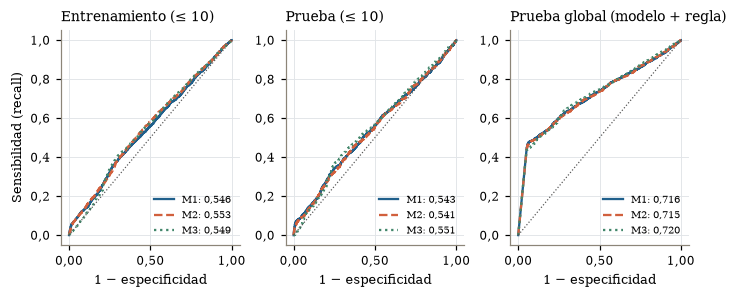

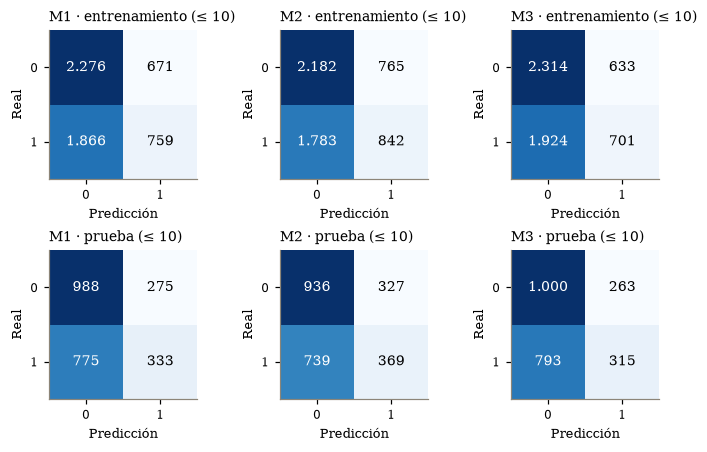

In [20]:
filas, predicciones_s3 = [], {}
for k, m in AJUSTES_S3.items():
    cols = columnas_s3(MODELOS[k]['numericas'] + MODELOS[k]['categoricas'])
    for conjunto, X, y in [('entrenamiento', X_train_s3, y_train_s3), ('prueba', X_test_s3, y_test_s3)]:
        prob = m.predict(sm.add_constant(X[cols], has_constant='add'))
        predicciones_s3[k, conjunto] = prob
        filas.append({'modelo': k, 'conjunto': conjunto, **metricas_clasificacion(y, prob)})
for conjunto, y in [('entrenamiento', y_train_s3), ('prueba', y_test_s3)]:
    mayoritaria = int(y_train_s3.mean() >= .5)
    filas.append({'modelo': 'clase_mayoritaria', 'conjunto': conjunto, **metricas_clasificacion(y, np.full(len(y), mayoritaria))})
metricas_s3 = pd.DataFrame(filas).set_index(['modelo', 'conjunto'])
metricas_s3.to_csv(TABLAS / 'modelos_metricas.csv')


def prob_combinada(k, conjunto):
    # Clasificador combinado: el modelo k para descuento <= 10 y la regla P_ALTO_S3 para descuento > 10
    total = train_total_s3 if conjunto == 'entrenamiento' else test_total_s3
    p = pd.Series(P_ALTO_S3, index=total.index)
    p.loc[predicciones_s3[k, conjunto].index] = predicciones_s3[k, conjunto]
    return p


filas = []
for k in AJUSTES_S3:
    for conjunto, total in [('entrenamiento', train_total_s3), ('prueba', test_total_s3)]:
        filas.append({'modelo': k, 'conjunto': conjunto, **metricas_clasificacion(total[TARGET], prob_combinada(k, conjunto))})
for conjunto, total in [('entrenamiento', train_total_s3), ('prueba', test_total_s3)]:
    filas.append({'modelo': 'clase_mayoritaria', 'conjunto': conjunto,
                  **metricas_clasificacion(total[TARGET], np.full(len(total), int(train_total_s3[TARGET].mean() >= .5)))})
metricas_combinadas_s3 = pd.DataFrame(filas).set_index(['modelo', 'conjunto'])
metricas_combinadas_s3.to_csv(TABLAS / 'modelos_metricas_combinadas.csv')

# Selección: tolerancia de 0,005 en el AUC de prueba del segmento y menor BIC
eleccion_s3 = resumen_modelos_s3.join(metricas_s3.xs('prueba', level='conjunto')[['auc', 'fn', 'fp']])
eleccion_s3['auc_combinado_prueba'] = metricas_combinadas_s3.xs('prueba', level='conjunto')['auc']
eleccion_s3['elegible_auc'] = eleccion_s3['auc'] >= eleccion_s3['auc'].max() - .005
MODELO_FINAL = eleccion_s3[eleccion_s3['elegible_auc']].sort_values(['bic', 'n_parametros']).index[0]
for razon in [1, 2, 5]:
    eleccion_s3[f'costo_fn_{razon}_fp_1'] = razon * eleccion_s3['fn'] + eleccion_s3['fp']
eleccion_s3['seleccionado'] = eleccion_s3.index == MODELO_FINAL
eleccion_s3.to_csv(TABLAS / 'modelos_seleccion.csv')

# Comparación con F2 (recomendación del profesor): AUC global 0,714 y AUC del segmento <= 10 = 0,521
f2_global = f2_modelo.loc['principal (imputación por mediana)']
f2_segmento = f2_modelo.loc['principal, prueba con descuento ≤ 10']
comparacion_f2_s3 = pd.DataFrame(
    [{'modelo': 'F2 (4 predictores, todos los envíos)', 'auc_segmento_le10': f2_segmento['auc'], 'auc_global': f2_global['auc'],
      'accuracy_segmento_le10': f2_segmento['accuracy'], 'accuracy_global': f2_global['accuracy']}]
    + [{'modelo': NOMBRE_MODELO[k], 'auc_segmento_le10': metricas_s3.loc[(k, 'prueba'), 'auc'],
        'auc_global': metricas_combinadas_s3.loc[(k, 'prueba'), 'auc'],
        'accuracy_segmento_le10': metricas_s3.loc[(k, 'prueba'), 'accuracy'],
        'accuracy_global': metricas_combinadas_s3.loc[(k, 'prueba'), 'accuracy']} for k in AJUSTES_S3]
    + [{'modelo': 'Clase mayoritaria', 'auc_segmento_le10': 0.5, 'auc_global': 0.5,
        'accuracy_segmento_le10': metricas_s3.loc[('clase_mayoritaria', 'prueba'), 'accuracy'],
        'accuracy_global': metricas_combinadas_s3.loc[('clase_mayoritaria', 'prueba'), 'accuracy']}]).set_index('modelo')
comparacion_f2_s3.to_csv(TABLAS / 'modelos_comparacion_f2.csv')
(RAIZ / 'outputs/modelo_final.json').write_text(json.dumps({'estrategia': ESTRATEGIA, 'modelo_final': MODELO_FINAL,
    'modelos': MODELOS, 'segmento': f'descuento <= {UMBRAL_SEGMENTO}', 'p_regla_descuento_mayor_10': P_ALTO_S3,
    'umbral': .5, 'tolerancia_auc': .005}, ensure_ascii=False, indent=2))
print('Métricas en el segmento descuento <= 10:'); display(metricas_s3.round(4))
print('Métricas del clasificador combinado (modelo <= 10 + regla > 10) sobre todos los envíos:'); display(metricas_combinadas_s3.round(4))
display(eleccion_s3.round(4))
print('Comparación con la Formativa 2 (conjunto de prueba):'); display(comparacion_f2_s3.round(4))
print('Modelo final:', NOMBRE_MODELO[MODELO_FINAL])

fig, axes = plt.subplots(1, 3, figsize=(ANCHO, 2.6))
roc_filas = []
paneles = [('entrenamiento', 'Entrenamiento (≤ 10)', 'segmento'), ('prueba', 'Prueba (≤ 10)', 'segmento'),
           ('prueba', 'Prueba global (modelo + regla)', 'combinado')]
for ax, (conjunto, titulo, nivel) in zip(axes, paneles):
    for k, color, estilo in zip(MODELOS, [AZUL, TERRA, VERDE], ['-', '--', ':']):
        if nivel == 'segmento':
            y, p, auc_k = (y_train_s3 if conjunto == 'entrenamiento' else y_test_s3), predicciones_s3[k, conjunto], metricas_s3.loc[(k, conjunto), 'auc']
        else:
            y, p, auc_k = test_total_s3[TARGET], prob_combinada(k, conjunto), metricas_combinadas_s3.loc[(k, conjunto), 'auc']
        fpr, tpr, thresholds = roc_curve(y, p)
        roc_filas.extend({'modelo': k, 'conjunto': conjunto, 'nivel': nivel, 'fpr': a, 'tpr': b, 'umbral': t} for a, b, t in zip(fpr, tpr, thresholds))
        ax.plot(fpr, tpr, color=color, ls=estilo, label=f'{k}: {num(auc_k, 3)}')
    ax.plot([0, 1], [0, 1], color=GRIS, ls=':', lw=.8)
    ax.set(xlabel='1 − especificidad', title=titulo)
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: num(x, 2)))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: num(x, 1)))
    ax.legend(fontsize=6.5, loc='lower right')
axes[0].set_ylabel('Sensibilidad (recall)')
pd.DataFrame(roc_filas).to_csv(TABLAS / 'modelos_roc.csv', index=False)
guardar('fig_3_3_roc', fig)
fig, axes = plt.subplots(2, 3, figsize=(ANCHO, 4))
for j, k in enumerate(MODELOS):
    for i, conjunto in enumerate(['entrenamiento', 'prueba']):
        r = metricas_s3.loc[k, conjunto]; mat = np.array([[r.vn, r.fp], [r.fn, r.vp]], dtype=int)
        ax = axes[i, j]; ax.imshow(mat, cmap='Blues'); ax.grid(False)
        for (a, b), valor in np.ndenumerate(mat):
            ax.text(b, a, num(valor), ha='center', va='center', color='white' if valor > mat.max() / 2 else 'black')
        ax.set(xticks=[0, 1], yticks=[0, 1], xlabel='Predicción', ylabel='Real', title=f'{k} · {conjunto} (≤ 10)')
guardar('fig_3_3_confusion', fig)

### 3.4 Estabilidad mediante *bootstrap*

**Responsable:** Yerko (implementación integrada por José) · **Recomendación de F2:** ver qué coeficientes conservan su signo.

**Método.** Igual que en S2, *bootstrap* no paramétrico por pares: se remuestrean con reemplazo los envíos del entrenamiento del segmento ≤ 10, con **B = 10.000** y el flujo `s3_bootstrap`. En cada remuestra se reajustan los tres modelos con las **mismas filas**, de modo que sus resultados son comparables. Para cada coeficiente se calculan:

- el IC 95 % **percentil** y **BCa**, con la función `intervalos_bootstrap` de S2 y una aceleración estimada por *jackknife*, comparados con el IC de **Wald**;
- el porcentaje de réplicas que **conservan el signo** de la estimación;
- la razón entre el EE *bootstrap* y el de Wald.

**Criterio de inestabilidad.** Un coeficiente es **inestable** si cumple al menos una condición:
- su IC BCa incluye el 0, equivalente a que el IC de su OR incluya el 1;
- menos del 97,5 % de las réplicas conserva su signo;
- el EE *bootstrap* supera en más de un 20 % al de Wald.

In [21]:
inicio_boot = time.perf_counter()
B_S3 = 10_000
rng_boot = generador('s3_bootstrap')
n_boot = len(y_train_s3)
y_np = y_train_s3.to_numpy(float)
DISENOS_BOOT = {k: sm.add_constant(X_train_s3[columnas_s3(MODELOS[k]['numericas'] + MODELOS[k]['categoricas'])],
                                   has_constant='add') for k in MODELOS}
REPLICAS_BOOT, JACK_BOOT = {k: np.empty((B_S3, d.shape[1])) for k, d in DISENOS_BOOT.items()}, {}
fallidas = {k: 0 for k in MODELOS}


def ajustar_np(X, y, inicio, tol=1e-10, max_iter=50):
    # Máxima verosimilitud del logit por Newton-Raphson (numpy), partiendo de la estimación completa
    beta = np.array(inicio, dtype=float)
    for _ in range(max_iter):
        p = 1 / (1 + np.exp(-(X @ beta)))
        paso = np.linalg.solve(X.T @ (X * (p * (1 - p))[:, None]), X.T @ (y - p))
        beta += paso
        if np.max(np.abs(paso)) < tol:
            return beta, True
    return beta, False


for k, X in DISENOS_BOOT.items():   # control: reproduce el ajuste de statsmodels con los datos completos
    np.testing.assert_allclose(ajustar_np(X.to_numpy(), y_np, np.zeros(X.shape[1]))[0], AJUSTES_S3[k].params.to_numpy(), rtol=1e-7, atol=1e-9)

for b in range(B_S3):
    idx = rng_boot.integers(0, n_boot, n_boot)   # mismas filas para los tres modelos
    for k, X in DISENOS_BOOT.items():
        params, ok = ajustar_np(X.to_numpy()[idx], y_np[idx], AJUSTES_S3[k].params.to_numpy())
        REPLICAS_BOOT[k][b] = params
        fallidas[k] += not ok
assert all(v == 0 for v in fallidas.values()), f'Remuestras sin convergencia: {fallidas}'
for k, X in DISENOS_BOOT.items():   # jackknife (sin cada envío) para la aceleración del BCa
    Xn, inicio = X.to_numpy(), AJUSTES_S3[k].params.to_numpy()
    JACK_BOOT[k] = np.array([ajustar_np(np.delete(Xn, i, 0), np.delete(y_np, i), inicio)[0] for i in range(n_boot)])

filas = []
for k, X in DISENOS_BOOT.items():
    m = AJUSTES_S3[k]
    ic_w = m.conf_int()
    for j, c in enumerate(X.columns):
        if c == 'const':
            continue
        est, rep = m.params[c], REPLICAS_BOOT[k][:, j]
        r = intervalos_bootstrap(rep, est, JACK_BOOT[k][:, j])
        fila = {'modelo': k, 'predictor': c, 'final': k == MODELO_FINAL, 'coef': est, 'ee_wald': m.bse[c], 'ee_bootstrap': r['ee'],
                'razon_ee': r['ee'] / m.bse[c], 'sesgo': r['sesgo'], 'ic_wald_inf': ic_w.loc[c, 0], 'ic_wald_sup': ic_w.loc[c, 1],
                'ic_percentil_inf': r['ic_percentil_inf'], 'ic_percentil_sup': r['ic_percentil_sup'],
                'ic_bca_inf': r['ic_bca_inf'], 'ic_bca_sup': r['ic_bca_sup'],
                'pct_conserva_signo': 100 * np.mean(np.sign(rep) == np.sign(est)), 'p_wald': m.pvalues[c]}
        for nombre in ['', '_inf', '_sup']:   # OR por 1 DE (exp de los extremos del coeficiente)
            base = {'': 'coef', '_inf': 'ic_bca_inf', '_sup': 'ic_bca_sup'}[nombre]
            fila['or_bca' + nombre if nombre else 'or'] = np.exp(fila[base])
        fila['or_wald_inf'], fila['or_wald_sup'] = np.exp(fila['ic_wald_inf']), np.exp(fila['ic_wald_sup'])
        fila['ic_bca_incluye_0'] = fila['ic_bca_inf'] <= 0 <= fila['ic_bca_sup']
        fila['ic_wald_incluye_0'] = fila['ic_wald_inf'] <= 0 <= fila['ic_wald_sup']
        motivos = [t for t, cond in [('IC BCa incluye 0', fila['ic_bca_incluye_0']),
                                     ('signo < 97,5 %', fila['pct_conserva_signo'] < 97.5),
                                     ('EE bootstrap > 1,2 × Wald', fila['razon_ee'] > 1.2)] if cond]
        fila['estabilidad'] = 'inestable' if motivos else 'estable'
        fila['motivo'] = '; '.join(motivos)
        filas.append(fila)
bootstrap_s3 = pd.DataFrame(filas)
bootstrap_s3.to_csv(TABLAS / 'bootstrap_coeficientes.csv', index=False)
pd.DataFrame(REPLICAS_BOOT[MODELO_FINAL], columns=DISENOS_BOOT[MODELO_FINAL].columns).to_csv(
    TABLAS / 'bootstrap_replicas_modelo_final.csv', index_label='replica')
print(f'Bootstrap: B = {num(B_S3)} remuestras de {num(n_boot)} envíos × 3 modelos, sin fallas de convergencia '
      f'({num(time.perf_counter() - inicio_boot, 0)} s).')
display(bootstrap_s3[['modelo', 'predictor', 'coef', 'ic_wald_inf', 'ic_wald_sup', 'ic_bca_inf', 'ic_bca_sup',
                      'razon_ee', 'pct_conserva_signo', 'or', 'or_bca_inf', 'or_bca_sup', 'estabilidad', 'motivo']].round(4))

Bootstrap: B = 10.000 remuestras de 5.572 envíos × 3 modelos, sin fallas de convergencia (43 s).


,modelo,predictor,coef,ic_wald_inf,ic_wald_sup,ic_bca_inf,ic_bca_sup,razon_ee,pct_conserva_signo,or,or_bca_inf,or_bca_sup,estabilidad,motivo
0,M1,peso_gramos,-0.1969,-0.2562,-0.1377,-0.2563,-0.1379,0.9952,100.00,0.8213,0.7739,0.8711,estable,
1,M1,descuento_ofrecido,-0.0228,-0.0757,0.0300,-0.0758,0.0298,0.9993,79.92,0.9774,0.9270,1.0303,inestable,"IC BCa incluye 0; signo < 97,5 %"
2,M1,costo_producto,-0.0551,-0.1124,0.0022,-0.1113,0.0021,0.9985,97.07,0.9464,0.8946,1.0021,inestable,"IC BCa incluye 0; signo < 97,5 %"
3,M1,compras_previas,-0.0772,-0.1331,-0.0213,-0.1349,-0.0215,1.0234,99.75,0.9257,0.8738,0.9787,estable,
4,M2,peso_gramos,-0.2031,-0.2629,-0.1434,-0.2635,-0.1429,0.9964,100.00,0.8162,0.7684,0.8668,estable,
5,M2,costo_producto,-0.0564,-0.1138,0.0010,-0.1129,0.0010,0.9997,97.38,0.9451,0.8933,1.0010,inestable,"IC BCa incluye 0; signo < 97,5 %"
6,M2,compras_previas,-0.0800,-0.1361,-0.0240,-0.1379,-0.0234,1.0262,99.78,0.9231,0.8712,0.9768,estable,
7,M2,importancia_producto_low,-0.2505,-0.4498,-0.0513,-0.4450,-0.0468,0.9966,99.36,0.7784,0.6408,0.9543,estable,
8,M2,importancia_producto_medium,-0.3230,-0.5234,-0.1225,-0.5222,-0.1204,1.0001,99.93,0.7240,0.5932,0.8866,estable,
9,M3,peso_gramos,-0.1533,-0.2060,-0.1005,-0.2067,-0.1001,1.0130,100.00,0.8579,0.8133,0.9047,estable,


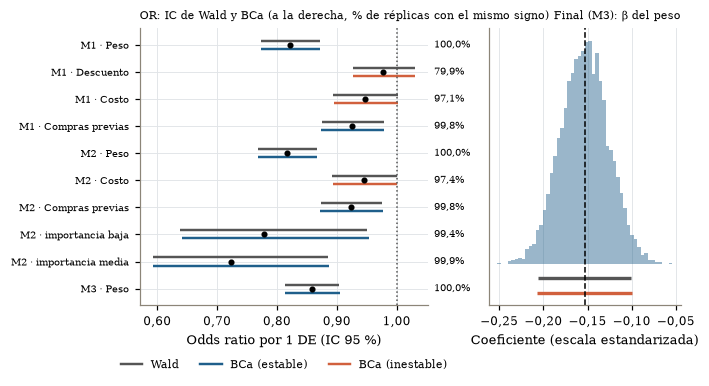

In [22]:
fig, ejes = plt.subplots(1, 2, figsize=(ANCHO, 3.4), width_ratios=[1.5, 1])
NIVEL_ES = {'low': 'baja', 'medium': 'media', 'high': 'alta'}
filas_fig = bootstrap_s3.iloc[::-1].reset_index(drop=True)
etiq_fila = [f"{r['modelo']} · {ETIQ.get(r['predictor'], r['predictor'].replace('importancia_producto_', 'importancia ').replace('bloque_bodega_', 'bodega: ').replace('modalidad_envio_', 'modalidad: ').replace('genero_', 'género: '))}"
             for _, r in filas_fig.iterrows()]
etiq_fila = [' '.join(NIVEL_ES.get(p, p) for p in e.split(' ')) for e in etiq_fila]
for i, (_, r) in enumerate(filas_fig.iterrows()):
    ejes[0].hlines(i + 0.15, r['or_wald_inf'], r['or_wald_sup'], color=GRIS, lw=1.6)
    ejes[0].hlines(i - 0.15, r['or_bca_inf'], r['or_bca_sup'], color=TERRA if r['estabilidad'] == 'inestable' else AZUL, lw=1.6)
    ejes[0].plot(r['or'], i, 'o', color='black', ms=3)
    ejes[0].text(1.0, i, f'  {num(r['pct_conserva_signo'], 1)}%', transform=ejes[0].get_yaxis_transform(), va='center', fontsize=6.5)
ejes[0].axvline(1, color=GRIS, ls=':', lw=1)
ejes[0].set_yticks(range(len(filas_fig)), etiq_fila, fontsize=6.5)
ejes[0].set_xlabel('Odds ratio por 1 DE (IC 95 %)')
ejes[0].xaxis.set_major_formatter(FuncFormatter(lambda x, _: num(x, 2)))
ejes[0].set_title('OR: IC de Wald y BCa (a la derecha, % de réplicas con el mismo signo)', fontsize=7)
ejes[0].legend([Line2D([], [], color=GRIS, lw=1.6), Line2D([], [], color=AZUL, lw=1.6), Line2D([], [], color=TERRA, lw=1.6)],
               ['Wald', 'BCa (estable)', 'BCa (inestable)'], fontsize=7, loc='upper center',
               bbox_to_anchor=(0.5, -0.16), ncol=3)
final = bootstrap_s3[bootstrap_s3['final']].iloc[0]
j = list(DISENOS_BOOT[MODELO_FINAL].columns).index(final['predictor'])
ejes[1].hist(REPLICAS_BOOT[MODELO_FINAL][:, j], bins=50, color=AZUL, alpha=0.45, density=True)
for (inf, sup, color, y) in [(final['ic_wald_inf'], final['ic_wald_sup'], GRIS, -0.06), (final['ic_bca_inf'], final['ic_bca_sup'], TERRA, -0.12)]:
    ejes[1].hlines(y * ejes[1].get_ylim()[1], inf, sup, color=color, lw=2.2)
ejes[1].axvline(final['coef'], color='black', ls='--', lw=1)
ejes[1].set_yticks([])
ejes[1].set_title(f"Final ({MODELO_FINAL}): β del {ETIQ.get(final['predictor'], final['predictor']).lower()}", fontsize=7, loc='right')
ejes[1].set_xlabel('Coeficiente (escala estandarizada)')
ejes[1].xaxis.set_major_formatter(FuncFormatter(lambda x, _: num(x, 2)))
guardar('fig_3_4_bootstrap', fig)

#### Interpretación del *bootstrap*

| Coeficiente | Wald IC 95 % | BCa IC 95 % | EE boot. / Wald | Conserva signo | Estabilidad |
|---|---|---|---:|---:|---|
| **M3 (final): peso** | [−0,206; −0,101] | [−0,207; −0,100] | 1,01 | **100 %** | **Estable** |
| M1: peso | [−0,256; −0,138] | [−0,256; −0,138] | 1,00 | 100 % | Estable |
| M1: compras previas | [−0,133; −0,021] | [−0,135; −0,022] | 1,02 | 99,8 % | Estable |
| M1: costo | [−0,112; 0,002] | [−0,111; 0,002] | 1,00 | 97,1 % | **Inestable** |
| M1: descuento | [−0,076; 0,030] | [−0,076; 0,030] | 1,00 | **79,9 %** | **Inestable** |
| M2: importancia baja / media | [−0,450; −0,051] / [−0,523; −0,123] | [−0,445; −0,047] / [−0,522; −0,120] | 1,00 | 99,4 % / 99,9 % | Estables |

- **El coeficiente del modelo final es estable.** El peso conserva su signo negativo en las 10.000 remuestras. Su IC BCa del OR por 1 DE es [0,813; 0,905], prácticamente igual al de Wald, y el sesgo *bootstrap* es despreciable (−0,0002).
- **Los inestables son los que S2 había marcado como sensibles.**
  - El **descuento** cambia de signo en una de cada cinco remuestras: dentro del segmento ≤ 10 no tiene un efecto definido.
  - El **costo** queda justo en el límite: su IC incluye el 0 y conserva el signo en el 97,1 % (97,4 % en M2).
- **El *bootstrap* coincide con los IC de Wald.** Los EE difieren a lo sumo un 3 %, porque con 5.572 envíos la aproximación normal de la máxima verosimilitud es adecuada, igual que en S2 con los parámetros de S1. El aporte del *bootstrap* no es corregir los IC, sino **mostrar qué coeficientes conservan su signo**. Eso confirma, con el modelo, la jerarquía de S1 y S2: el peso es robusto, compras previas e importancia son estables pero pequeños, y descuento y costo dentro del segmento no son estables.
- **Límite:** el *bootstrap* remuestrea envíos del dataset imputado, así que no incorpora la incertidumbre de la imputación ni la de la selección del modelo.

### 3.5 Diagnóstico

- **VIF:** se calcula con intercepto y todas las columnas de cada modelo. Los valores 5 y 10 son referencias de revisión, no fronteras universales. Como referencia, en F2 ningún VIF superó 1,25.
- **Linealidad en el logit (Box–Tidwell):** agrega simultáneamente términos x·log(x) para las numéricas del modelo final, estrictamente positivas, junto a sus efectos lineales. Los valores *p* se ajustan por Holm y se reporta la prueba conjunta. Los logit empíricos por deciles usan corrección de 0,5 y son asociaciones marginales, no efectos ajustados.
- **Influencia:** se evalúa con el GLM binomial equivalente al Logit. Se marca una alerta si Cook > 4/*n*, si *leverage* > 2*p*/*n* o si el máximo |DFBETAS| > 2/√*n*. Son alertas para un análisis de sensibilidad, no motivos automáticos de eliminación.
- **Residuos:** los binomiales no tienen por qué ser normales; se examinan patrones en los residuos de *deviance*, de Pearson y agrupados.

modelo  predictor                  
M1      peso_gramos                    1.246
        descuento_ofrecido             1.000
        costo_producto                 1.175
        compras_previas                1.091
M2      peso_gramos                    1.264
        costo_producto                 1.176
        compras_previas                1.098
        importancia_producto_low       3.561
        importancia_producto_medium    3.523
M3      peso_gramos                    1.000
Name: vif, dtype: float64

,vif_f2_todos_los_envios,vif_s3_M1_segmento
peso_gramos,1.248,1.246
descuento_ofrecido,1.222,1.000
costo_producto,1.062,1.175
compras_previas,1.061,1.091


,dataset,segmento,rho_peso_descuento
0,original,todos,-0.316
1,original,descuento <= 10,0.007
2,regresion,todos,-0.359
3,regresion,descuento <= 10,-0.005


,coef_xlogx,p,p_holm,rechaza_linealidad_005
peso_gramos_xlogx,-6.655968,0.000001,0.000001,True


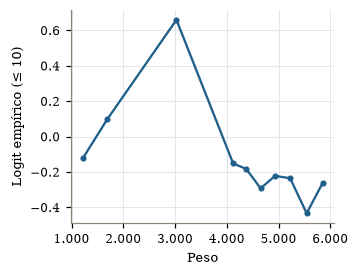

In [23]:
def vif_s3(X):
    A = sm.add_constant(X, has_constant='add')
    if A.shape[1] == 2:   # un solo predictor: no hay otros con los que compartir varianza
        return pd.Series({c: 1.0 for c in A.columns if c != 'const'}, name='vif')
    return pd.Series({c: variance_inflation_factor(A.to_numpy(float), i) for i, c in enumerate(A.columns) if c != 'const'}, name='vif')
vifs_s3 = pd.concat({k: vif_s3(X_train_s3[columnas_s3(s['numericas'] + s['categoricas'])]) for k, s in MODELOS.items()}, names=['modelo', 'predictor'])
vifs_s3.to_csv(TABLAS / 'modelos_vif.csv')
f2_vif = pd.read_csv(F2 / 'outputs/tablas/vif.csv', index_col=0)['vif']
vif_comparado = pd.DataFrame({'vif_f2_todos_los_envios': f2_vif, 'vif_s3_M1_segmento': vifs_s3.loc['M1']})
correlacion_s3 = pd.DataFrame([{'dataset': k, 'segmento': s, 'rho_peso_descuento': d.peso_gramos.corr(d.descuento_ofrecido, method='spearman')}
                              for k, d0 in [('original', df), ('regresion', DATASETS['regresion'])]
                              for s, d in [('todos', d0), ('descuento <= 10', d0[en_segmento(d0)])]])
correlacion_s3.to_csv(TABLAS / 'modelos_correlacion_peso_descuento.csv', index=False)
spec_final_s3 = MODELOS[MODELO_FINAL]
cols_final_s3 = columnas_s3(spec_final_s3['numericas'] + spec_final_s3['categoricas'])
X_final_s3 = sm.add_constant(X_train_s3[cols_final_s3], has_constant='add')
modelo_final_s3 = AJUSTES_S3[MODELO_FINAL]
X_bt = X_final_s3.copy(); terminos_bt = []
for v in spec_final_s3['numericas']:
    x = train_s3[v].astype(float)
    assert x.min() > 0, 'Box–Tidwell requiere valores positivos.'
    termino = v + '_xlogx'; terminos_bt.append(termino)
    z = x * np.log(x)
    X_bt[termino] = (z - z.mean()) / z.std(ddof=1)
modelo_bt = ajustar_logit(X_bt.drop(columns='const'), y_train_s3)
bt_s3 = pd.DataFrame({'coef_xlogx': modelo_bt.params[terminos_bt], 'p': modelo_bt.pvalues[terminos_bt]})
bt_s3['p_holm'] = multipletests(bt_s3['p'], method='holm')[1]
bt_s3['rechaza_linealidad_005'] = bt_s3.p_holm < .05
bt_s3.to_csv(TABLAS / 'modelos_box_tidwell.csv')
pd.DataFrame([{'lr': 2 * (modelo_bt.llf - modelo_final_s3.llf), 'gl': len(terminos_bt),
               'p': p_lr_s3(modelo_bt, modelo_final_s3)}]).to_csv(TABLAS / 'modelos_box_tidwell_conjunto.csv', index=False)
display(vifs_s3.round(3)); display(vif_comparado.round(3)); display(correlacion_s3.round(3)); display(bt_s3)
variables_logit = spec_final_s3['numericas'] or NUM_S3
fig, axes = plt.subplots(1, len(variables_logit), figsize=(ANCHO if len(variables_logit) > 1 else ANCHO / 2, 2.4), squeeze=False)
logit_filas = []
for ax, v in zip(axes[0], variables_logit):
    tmp = pd.DataFrame({'x': train_s3[v], 'y': y_train_s3})
    grupos = tmp.groupby(pd.qcut(tmp.x, 10, duplicates='drop'), observed=True).agg(x=('x', 'mean'), n=('y', 'size'), atrasos=('y', 'sum'))
    grupos['logit'] = np.log((grupos.atrasos + .5) / (grupos.n - grupos.atrasos + .5))
    ax.plot(grupos.x, grupos.logit, 'o-', color=AZUL, ms=3); ax.set(xlabel=ETIQ[v], ylabel='Logit empírico (≤ 10)')
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: num(x)))
    logit_filas.append(grupos.assign(variable=v).reset_index(drop=True))
pd.concat(logit_filas).to_csv(TABLAS / 'modelos_logit_empirico.csv', index=False)
guardar('fig_3_5_logit_empirico', fig)

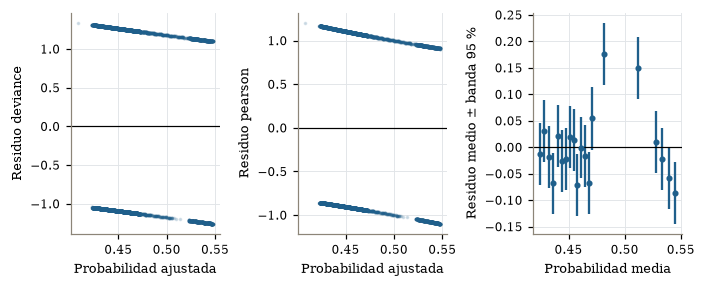

,coef_completo,ee_completo,z_completo,p_completo,ic_inf_completo,ic_sup_completo,or_completo,or_inf_completo,or_sup_completo,or_unidad_completo,...,ic_inf_sin_alertas,ic_sup_sin_alertas,or_sin_alertas,or_inf_sin_alertas,or_sup_sin_alertas,or_unidad_sin_alertas,or_unidad_inf_sin_alertas,or_unidad_sup_sin_alertas,unidad_sin_alertas,cambio_or_pct
peso_gramos,-0.1533,0.0269,-5.6921,0.0,-0.206,-0.1005,0.8579,0.8138,0.9044,0.9045,...,-0.3094,-0.1763,0.7844,0.7339,0.8384,0.853,0.8166,0.891,1.000 g,-8.5722


Filas señaladas para sensibilidad: 523 de 5572


In [24]:
glm_s3 = sm.GLM(y_train_s3, X_final_s3, family=sm.families.Binomial()).fit()
assert np.allclose(glm_s3.params, modelo_final_s3.params, atol=1e-6)
influencia_s3 = glm_s3.get_influence()
n_s3, p_s3 = X_final_s3.shape
infl_s3 = pd.DataFrame({'id_envio': train_s3.id_envio, 'cook': influencia_s3.cooks_distance[0],
                        'leverage': influencia_s3.hat_matrix_diag,
                        'max_abs_dfbetas': np.abs(influencia_s3.dfbetas).max(axis=1),
                        'resid_deviance': glm_s3.resid_deviance, 'resid_pearson': glm_s3.resid_pearson})
infl_s3['alerta_cook'] = infl_s3.cook > 4/n_s3
infl_s3['alerta_leverage'] = infl_s3.leverage > 2*p_s3/n_s3
infl_s3['alerta_dfbetas'] = infl_s3.max_abs_dfbetas > 2/np.sqrt(n_s3)
infl_s3['alerta'] = infl_s3[['alerta_cook','alerta_leverage','alerta_dfbetas']].any(axis=1)
infl_s3.to_csv(TABLAS / 'modelos_influencia.csv', index_label='indice')
pd.DataFrame(influencia_s3.dfbetas, index=train_s3.index, columns=X_final_s3.columns).to_csv(TABLAS / 'modelos_dfbetas.csv', index_label='indice')
sin_alertas_s3 = ajustar_logit(X_final_s3.loc[~infl_s3.alerta].drop(columns='const'), y_train_s3.loc[~infl_s3.alerta])
or_sens_s3 = tabla_odds_ratios(modelo_final_s3, ESCALAS_S3).join(tabla_odds_ratios(sin_alertas_s3, ESCALAS_S3), lsuffix='_completo', rsuffix='_sin_alertas')
or_sens_s3['cambio_or_pct'] = 100*(or_sens_s3.or_sin_alertas/or_sens_s3.or_completo-1)
or_sens_s3.to_csv(TABLAS / 'modelos_sensibilidad_influencia.csv')
pd.DataFrame([{'n': n_s3, 'n_alertas': int(infl_s3.alerta.sum()), 'umbral_cook': 4/n_s3,
               'umbral_leverage': 2*p_s3/n_s3, 'umbral_dfbetas': 2/np.sqrt(n_s3)}]).to_csv(TABLAS / 'modelos_influencia_resumen.csv', index=False)
prob_s3 = glm_s3.fittedvalues
res = pd.DataFrame({'prob': prob_s3, 'resid': y_train_s3-prob_s3, 'var': prob_s3*(1-prob_s3)})
binned_s3 = res.groupby(pd.qcut(res.prob, 20, duplicates='drop'), observed=True).agg(prob=('prob','mean'), resid=('resid','mean'), n=('resid','size'), var_suma=('var','sum'))
binned_s3['banda_95'] = 1.96*np.sqrt(binned_s3.var_suma)/binned_s3.n
binned_s3.to_csv(TABLAS / 'modelos_residuos_agrupados.csv')
fig, axes = plt.subplots(1,3,figsize=(ANCHO,2.5))
for ax,c in zip(axes[:2], ['resid_deviance','resid_pearson']):
    ax.scatter(prob_s3, infl_s3[c], s=2, alpha=.15, color=AZUL, rasterized=True)
    ax.axhline(0,color='black',lw=.8); ax.set(xlabel='Probabilidad ajustada', ylabel=c.replace('resid_', 'Residuo '))
axes[2].errorbar(binned_s3.prob, binned_s3.resid, yerr=binned_s3.banda_95, fmt='o', ms=3, color=AZUL)
axes[2].axhline(0,color='black',lw=.8); axes[2].set(xlabel='Probabilidad media', ylabel='Residuo medio ± banda 95 %')
guardar('fig_3_5_residuos', fig)
display(or_sens_s3.round(4))
print('Filas señaladas para sensibilidad:', int(infl_s3.alerta.sum()), 'de', n_s3)


#### Sensibilidad al ajuste de la imputación y a la asignación del segmento

- **Imputación ajustada solo con el entrenamiento.** Se mantienen la especificación final y la partición, pero las regresiones de imputación, las medianas y los límites de recorte se reestiman usando solo las filas de entrenamiento, con la misma regla de la Parte 1. Luego se reajusta el modelo final en su segmento.
- **Segmento asignado con el descuento original.** Se evalúa el modelo final en los envíos de prueba cuyo descuento **original** es ≤ 10. Esto es posible solo porque los faltantes son simulados, y muestra el desempeño sin errores de asignación del segmento.

In [25]:
falt_train_s3 = df_faltantes.loc[IDX_TRAIN]
med_train_s3 = falt_train_s3[VARS_FALTANTES].median()
datos_imp_train_s3 = df_faltantes.copy()
for v in VARS_FALTANTES:
    observado = falt_train_s3[[v] + PREDICTORES[v]].dropna()
    imp = sm.OLS(observado[v], sm.add_constant(observado[PREDICTORES[v]], has_constant='add')).fit()
    faltan = df_faltantes[v].isna()
    X_imp = df_faltantes.loc[faltan, PREDICTORES[v]].fillna(med_train_s3)
    pred = imp.predict(sm.add_constant(X_imp, has_constant='add'))
    datos_imp_train_s3.loc[faltan, v] = pred.clip(falt_train_s3[v].min(), falt_train_s3[v].max()).round()
assert datos_imp_train_s3.notna().all().all()
tr_sens_tot, te_sens_tot = particionar(datos_imp_train_s3)
tr_sens, te_sens = tr_sens_tot[en_segmento(tr_sens_tot)], te_sens_tot[en_segmento(te_sens_tot)]
X_tr_sens = disenar(tr_sens, spec_final_s3['numericas'], spec_final_s3['categoricas'], tr_sens)
X_te_sens = disenar(te_sens, spec_final_s3['numericas'], spec_final_s3['categoricas'], tr_sens)
m_sens = ajustar_logit(X_tr_sens, tr_sens[TARGET])
p_sens = m_sens.predict(sm.add_constant(X_te_sens, has_constant='add'))
# Segmento por descuento original: mismas filas de prueba de la partición, valores del dataset elegido
real_bajo = df.loc[test_total_s3.index, 'descuento_ofrecido'] <= UMBRAL_SEGMENTO
prueba_real_seg = test_total_s3[real_bajo]
p_real_seg = modelo_final_s3.predict(sm.add_constant(disenar(prueba_real_seg, spec_final_s3['numericas'], spec_final_s3['categoricas'], train_s3), has_constant='add'))
sens_eval_s3 = pd.DataFrame([
    {'escenario': 'dataset_acordado (segmento por descuento imputado)', **metricas_clasificacion(y_test_s3, predicciones_s3[MODELO_FINAL, 'prueba'])},
    {'escenario': 'imputacion_ajustada_solo_train', **metricas_clasificacion(te_sens[TARGET], p_sens)},
    {'escenario': 'segmento_por_descuento_original', **metricas_clasificacion(prueba_real_seg[TARGET], p_real_seg)},
]).set_index('escenario')
sens_eval_s3.to_csv(TABLAS / 'modelos_sensibilidad_evaluacion.csv')
escalas_sens = {v: (u, tr_sens[v].std(ddof=1), etiqueta) for v, (u, etiqueta) in UNIDADES_S3.items()}
tabla_odds_ratios(m_sens, escalas_sens).to_csv(TABLAS / 'modelos_or_imputacion_solo_train.csv')
display(sens_eval_s3.round(4))
assert set(MODELOS) == {'M1', 'M2', 'M3'} and MODELO_FINAL in MODELOS
assert all(m.mle_retvals['converged'] for m in CACHE_S3.values())
assert np.isfinite(coeficientes_s3[['coef', 'ee', 'or']].to_numpy()).all()

,n,vp,fp,fn,vn,accuracy,precision,recall,f1,especificidad,auc
escenario,,,,,,,,,,,
dataset_acordado (segmento por descuento imputado),2371,315,263,793,1000,0.5546,0.5450,0.2843,0.3737,0.7918,0.5508
imputacion_ajustada_solo_train,2370,314,262,794,1000,0.5544,0.5451,0.2834,0.3729,0.7924,0.5506
segmento_por_descuento_original,2493,342,286,820,1045,0.5564,0.5446,0.2943,0.3821,0.7851,0.5509


#### Interpretación de resultados de la Parte 2

**Segmentación.** El entrenamiento tiene 5.572 envíos con descuento ≤ 10 (47,1 % de atraso) y 2.127 con descuento > 10. Con el descuento imputado, la tasa de atraso de estos últimos es 92,6 %, no el 100 % de S1: la imputación por regresión asignó al segmento > 10 algunos envíos cuyo descuento real era ≤ 10 (Parte 3).

**Los tres modelos del segmento ≤ 10:**

| Modelo | Variables | AIC | BIC | AUC prueba ≤ 10 | AUC global (modelo + regla) |
|---|---|---:|---:|---:|---:|
| M1 · variables actuales | peso, descuento, costo, compras | 7.671,0 | 7.704,2 | 0,543 | 0,716 |
| M2 · *stepwise* AIC | peso, compras, importancia, costo | **7.663,6** | 7.703,4 | 0,541 | 0,715 |
| M3 · reducido (BIC) | **peso** | 7.677,3 | **7.690,5** | **0,551** | **0,720** |

- **El *stepwise* por AIC** incorpora, en orden, peso, compras previas, importancia y costo; nunca incluye el descuento.
- **El modelo reducido conserva solo el peso.** Es exactamente lo que anticipó S2: el peso es la única asociación robusta en todos los escenarios, y la del descuento existe solo por el segmento > 10.
- **Dentro del segmento, el descuento no aporta** (OR por unidad 0,99; *p* = 0,40), y el costo queda en el límite (*p* = 0,06).

**Interpretación de los OR (manteniendo constantes los demás predictores):**
- **Peso:** en M3, cada 1.000 g adicionales reducen las chances de atraso un 9,5 % (OR 0,905; IC 95 % 0,874–0,936). En M1, ajustado por los demás, un 12,1 % (OR 0,879).
- **Compras previas:** cada compra adicional reduce las chances un 5,2 % (OR 0,948 en M1).
- **Importancia (M2):** baja y media tienen chances de atraso un 22 % y un 28 % menores que alta (OR 0,778 y 0,724), coherente con la prueba E2 de S1.

**Selección del modelo final: M3 (reducido).** Es el único dentro de 0,005 del mayor AUC de prueba en el segmento y tiene el menor BIC. La diferencia de AUC entre modelos (0,010) es pequeña y no prueba superioridad. Lo decisivo es que M3 logra lo mismo con un solo predictor, el más robusto de S1 y S2.

**Desempeño frente a F2** (recomendación del profesor):
- en el segmento ≤ 10, el AUC sube de **0,521 a 0,551**, y la accuracy pasa de 0,508, bajo la línea base, a 0,555, sobre la línea base de 0,533;
- en el clasificador combinado, el AUC sube de **0,714 a 0,720** y la accuracy, de 0,628 a 0,659.

La mejora es real pero modesta: fuera del descuento alto, los datos tienen poca señal para anticipar el atraso.

**Métricas del modelo final en la prueba (umbral 0,5):**
- **Segmento ≤ 10:** precision 0,545, recall 0,284 y especificidad 0,792. Con probabilidades cercanas a 0,5, el modelo es conservador: alerta pocos atrasos.
- **Clasificador combinado:**
  - accuracy 0,659, precision 0,780, recall 0,597, F1 0,677 y especificidad 0,751;
  - frente a F2, gana especificidad (0,751 frente a 0,538) y precision, y pierde recall;
  - el F1 de la clase mayoritaria (0,747) sigue siendo mayor, porque predecir siempre "atrasado" tiene recall 1, pero esa regla no distingue ningún envío puntual.

**Diagnóstico:**
- **VIF:** ≤ 1,26 en las variables numéricas. Las *dummies* de importancia muestran VIF de 3,5 por compartir la misma referencia; no es multicolinealidad entre predictores distintos.
- **Correlación peso–descuento:** dentro del segmento es ≈ 0 (−0,005), así que la confusión entre ambos que había en el modelo global desaparece.
- **Linealidad (Box–Tidwell):** la rechaza para el peso (*p* < 0,001), coherente con su distribución bimodal (S1). El logit empírico por deciles muestra un efecto no monótono.
- **Influencia:** 523 de 5.572 filas tienen alguna alerta. Sin ellas, el OR del peso pasa de 0,905 a 0,853: misma dirección, más intenso. Se conservan, porque son envíos válidos.
- **Sensibilidad:** ajustar la imputación solo con el entrenamiento (AUC 0,551) o asignar el segmento con el descuento original (AUC 0,551) no cambia el resultado.

## 4. Parte 3: impacto de la estrategia de imputación

**Responsable:** José · **Revisor:** Yerko

**Rúbrica (9 pts):** comparar sistemáticamente los tres datasets; impacto en coeficientes, IC y desempeño; recomendaciones fundamentadas.

**Diseño.** El modelo final (`MODELOS[MODELO_FINAL]`) se reajusta con cada uno de los tres `DATASETS` de la Parte 1. Se repite el mismo flujo de la Parte 2: partición común, segmento con descuento ≤ 10 según los valores de cada dataset, preparación con `disenar` y regla para el segmento > 10. Así, las diferencias entre estrategias se deben **solo al tratamiento de los faltantes**.

Como los faltantes son simulados, se agregan dos referencias que no existirían con faltantes reales:

1. **Datos originales sin faltantes:** el mismo flujo con los valores verdaderos, para medir cuánto se aleja cada estrategia de la estimación sin faltantes.
2. **Conjunto de prueba común con valores reales:** los modelos se evalúan además en los mismos 3.300 envíos de prueba, con sus valores **originales** y su segmento real. Las diferencias de desempeño se deben así a los coeficientes estimados, y no a qué envíos quedaron en la prueba ni a valores imputados en ella.

**Comparación:**
- tamaño muestral;
- envíos asignados al segmento equivocado por la imputación del descuento;
- coeficientes y odds ratios con su IC 95 %;
- conservación del signo y de la significancia;
- AUC y accuracy en el segmento ≤ 10 y en el clasificador combinado.

In [26]:
# Parte 3: modelo final con cada estrategia de imputación y con los datos originales como referencia
ESPEC_FINAL = MODELOS[MODELO_FINAL]
NUM_FINAL, CAT_FINAL = ESPEC_FINAL['numericas'], ESPEC_FINAL['categoricas']
ESTRATEGIAS_P3 = {'eliminacion': 'Eliminación', 'mediana': 'Mediana', 'regresion': 'Regresión (elegida)',
                  'original': 'Original sin faltantes (referencia)'}
_, test_original = particionar(df)
real_bajo_original = en_segmento(df)

filas_coef, filas_desemp, filas_seg, AJUSTES_P3 = [], [], [], {}
for clave in ESTRATEGIAS_P3:
    datos = df if clave == 'original' else DATASETS[clave]
    tr_tot, te_tot = particionar(datos)
    tr, te = tr_tot[en_segmento(tr_tot)], te_tot[en_segmento(te_tot)]
    p_alto = tr_tot.loc[~en_segmento(tr_tot), TARGET].mean()
    modelo = ajustar_logit(disenar(tr, NUM_FINAL, CAT_FINAL, tr), tr[TARGET])
    AJUSTES_P3[clave] = modelo
    escalas = {v: (u, tr[v].std(ddof=1), etiqueta) for v, (u, etiqueta) in UNIDADES_S3.items() if v in NUM_FINAL}
    coef = tabla_odds_ratios(modelo, escalas).reset_index(names='predictor')
    coef.insert(0, 'estrategia', clave)
    filas_coef.append(coef)
    asignado_bajo, real_bajo = en_segmento(datos), real_bajo_original.loc[datos.index]
    filas_seg.append({'estrategia': clave, 'envios': len(datos), 'entrenamiento_segmento': len(tr), 'prueba_segmento': len(te),
                      'tasa_regla_mayor_10': p_alto,
                      'real_le10_asignado_mayor_10': int((~asignado_bajo & real_bajo).sum()),
                      'real_mayor_10_asignado_le10': int((asignado_bajo & ~real_bajo).sum())})


    def evaluar(prueba_tot, en_bajo):
        # Probabilidades del clasificador combinado y del segmento <= 10
        p = pd.Series(p_alto, index=prueba_tot.index)
        bajo = prueba_tot[en_bajo]
        p.loc[bajo.index] = modelo.predict(sm.add_constant(disenar(bajo, NUM_FINAL, CAT_FINAL, tr), has_constant='add'))
        return p, bajo.index


    for evaluacion, prueba_tot, mascara in [('prueba propia', te_tot, en_segmento(te_tot)),
                                            ('prueba común con valores reales', test_original, real_bajo_original.loc[test_original.index])]:
        p, idx_bajo = evaluar(prueba_tot, mascara)
        for nivel, y, pp in [('segmento <= 10', prueba_tot.loc[idx_bajo, TARGET], p.loc[idx_bajo]), ('combinado', prueba_tot[TARGET], p)]:
            filas_desemp.append({'estrategia': clave, 'evaluacion': evaluacion, 'nivel': nivel, **metricas_clasificacion(y, pp)})

coef_p3 = pd.concat(filas_coef, ignore_index=True)
desemp_p3 = pd.DataFrame(filas_desemp)
segmento_p3 = pd.DataFrame(filas_seg).set_index('estrategia')
# Control: con la estrategia elegida se reproduce el ajuste de la Parte 2
np.testing.assert_allclose(AJUSTES_P3[ESTRATEGIA].params.to_numpy(), AJUSTES_S3[MODELO_FINAL].params.to_numpy(), rtol=1e-10)

ref_eleg = coef_p3[coef_p3['estrategia'] == ESTRATEGIA].set_index('predictor')
ref_orig = coef_p3[coef_p3['estrategia'] == 'original'].set_index('predictor')
coef_p3['or_comparable'] = coef_p3['or_unidad'].fillna(coef_p3['or'])
coef_p3['or_comparable_inf'] = coef_p3['or_unidad_inf'].fillna(coef_p3['or_inf'])
coef_p3['or_comparable_sup'] = coef_p3['or_unidad_sup'].fillna(coef_p3['or_sup'])
ancho = coef_p3['or_comparable_sup'] - coef_p3['or_comparable_inf']
ancho_eleg = coef_p3['predictor'].map((ref_eleg['or_unidad_sup'].fillna(ref_eleg['or_sup']) - ref_eleg['or_unidad_inf'].fillna(ref_eleg['or_inf'])))
coef_p3['razon_ancho_vs_elegida'] = ancho / ancho_eleg
or_orig = coef_p3['predictor'].map(ref_orig['or_unidad'].fillna(ref_orig['or']))
coef_p3['cambio_or_vs_original_pct'] = 100 * (coef_p3['or_comparable'] / or_orig - 1)
coef_p3['original_dentro_del_ic'] = or_orig.between(coef_p3['or_comparable_inf'], coef_p3['or_comparable_sup'])
coef_p3['mismo_signo_que_original'] = np.sign(coef_p3['coef']) == np.sign(coef_p3['predictor'].map(ref_orig['coef']))
coef_p3['significativo_5pct'] = coef_p3['p'] < 0.05
coef_p3.to_csv(TABLAS / 'impacto_imputacion_coeficientes.csv', index=False)
desemp_p3.to_csv(TABLAS / 'impacto_imputacion_desempeno.csv', index=False)
segmento_p3.to_csv(TABLAS / 'impacto_imputacion_segmento.csv')

print('Tamaño muestral y asignación del segmento por estrategia:')
display(segmento_p3.round(4))
display(coef_p3[['estrategia', 'predictor', 'coef', 'p', 'or_comparable', 'or_comparable_inf', 'or_comparable_sup',
                 'razon_ancho_vs_elegida', 'cambio_or_vs_original_pct', 'original_dentro_del_ic', 'mismo_signo_que_original',
                 'significativo_5pct']].round(4))
display(desemp_p3.pivot_table(index='estrategia', columns=['evaluacion', 'nivel'], values=['auc', 'accuracy'])
        .reindex(list(ESTRATEGIAS_P3)).round(4))

Tamaño muestral y asignación del segmento por estrategia:


,envios,entrenamiento_segmento,prueba_segmento,tasa_regla_mayor_10,real_le10_asignado_mayor_10,real_mayor_10_asignado_le10
estrategia,,,,,,
eliminacion,7213,3840,1635,1.0000,0,0
mediana,10999,6043,2577,1.0000,0,268
regresion,10999,5572,2371,0.9257,428,19
original,10999,5859,2493,1.0000,0,0


,estrategia,predictor,coef,p,or_comparable,or_comparable_inf,or_comparable_sup,razon_ancho_vs_elegida,cambio_or_vs_original_pct,original_dentro_del_ic,mismo_signo_que_original,significativo_5pct
0,eliminacion,peso_gramos,-0.1708,0.0,0.8994,0.8645,0.9356,1.1366,-0.4361,True,True,True
1,mediana,peso_gramos,-0.2104,0.0,0.8725,0.8441,0.9018,0.9219,-3.4144,False,True,True
2,regresion,peso_gramos,-0.1533,0.0,0.9045,0.8738,0.9363,1.0000,0.1343,True,True,True
3,original,peso_gramos,-0.1635,0.0,0.9033,0.8748,0.9327,0.9250,0.0000,True,True,True


accuracy                               \
evaluacion  prueba común con valores reales                prueba propia   
nivel                             combinado segmento <= 10     combinado   
estrategia                                                                 
eliminacion                          0.6667         0.5588        0.6673   
mediana                              0.6748         0.5696        0.6652   
regresion                            0.6670         0.5592        0.6594   
original                             0.6667         0.5588        0.6667   

                                                       auc                 \
evaluacion                 prueba común con valores reales                  
nivel       segmento <= 10                       combinado segmento <= 10   
estrategia                                                                  
eliminacion         0.5615                          0.7363         0.5532   
mediana             0.5712                          0.7363         0.5532   
regresion           0.5546                          0.7363         0.5532   
original            0.5588                          0.7363         0.5532   

                                          
evaluacion  prueba propia                 
nivel           combinado segmento <= 10  
estrategia                                
eliminacion        0.7335         0.5509  
mediana            0.7292         0.5721  
regresion          0.7202         0.5508  
original           0.7363         0.5532

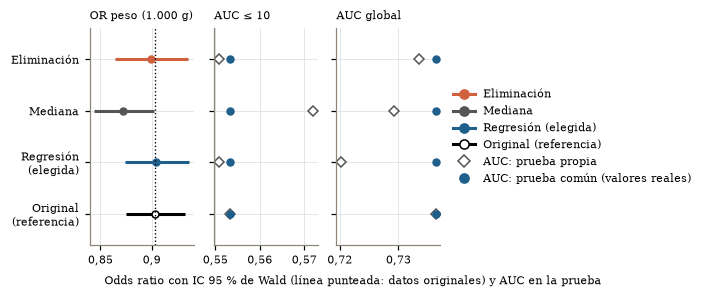

In [27]:
COLOR_P3 = {'eliminacion': TERRA, 'mediana': GRIS, 'regresion': AZUL, 'original': 'black'}
ETIQ_P3 = {'eliminacion': 'Eliminación', 'mediana': 'Mediana', 'regresion': 'Regresión\n(elegida)', 'original': 'Original\n(referencia)'}
FMT_EJE = FuncFormatter(lambda x, _: num(x, 3).rstrip('0').rstrip(','))
predictores_p3 = list(dict.fromkeys(coef_p3['predictor']))
paneles = predictores_p3 + ['auc_segmento', 'auc_combinado']
ncol = min(4, len(paneles) + 1)   # un panel extra para la leyenda
nfil = int(np.ceil((len(paneles) + 1) / ncol))
fig, ejes = plt.subplots(nfil, ncol, figsize=(ANCHO, 2.1 * nfil + 0.5), squeeze=False)
posiciones = np.arange(len(ESTRATEGIAS_P3))[::-1]
for ax, panel in zip(ejes.flat, paneles):
    if panel in predictores_p3:
        for y, clave in zip(posiciones, ESTRATEGIAS_P3):
            r = coef_p3[(coef_p3['estrategia'] == clave) & (coef_p3['predictor'] == panel)].iloc[0]
            ax.hlines(y, r['or_comparable_inf'], r['or_comparable_sup'], color=COLOR_P3[clave], lw=2)
            ax.plot(r['or_comparable'], y, 'o', color=COLOR_P3[clave], ms=4.5, mfc='white' if clave == 'original' else COLOR_P3[clave])
        r0 = coef_p3[(coef_p3['estrategia'] == 'original') & (coef_p3['predictor'] == panel)].iloc[0]
        ax.axvline(r0['or_comparable'], color='black', ls=':', lw=0.9)
        unidad = UNIDADES_S3[panel][1] if panel in UNIDADES_S3 else 'nivel vs. referencia'
        ax.set_title(f"OR {ETIQ.get(panel, panel).lower()} ({unidad})", fontsize=7.5)
    else:
        nivel = 'segmento <= 10' if panel == 'auc_segmento' else 'combinado'
        for evaluacion, marcador, color, relleno in [('prueba propia', 'D', GRIS, 'white'), ('prueba común con valores reales', 'o', AZUL, AZUL)]:
            v = desemp_p3[(desemp_p3['evaluacion'] == evaluacion) & (desemp_p3['nivel'] == nivel)].set_index('estrategia').loc[list(ESTRATEGIAS_P3), 'auc']
            ax.plot(v, posiciones, marcador, color=color, ms=4.5, mfc=relleno)
        ax.set_title('AUC ≤ 10' if panel == 'auc_segmento' else 'AUC global', fontsize=7.5)
    ax.xaxis.set_major_formatter(FMT_EJE)
    ax.tick_params(axis='x', labelsize=7)
    ax.set_yticks(posiciones, [ETIQ_P3[k] for k in ESTRATEGIAS_P3] if ax is ejes[ax.get_subplotspec().rowspan.start, 0] else [], fontsize=7)
    ax.set_ylim(-0.6, len(ESTRATEGIAS_P3) - 0.4)
for ax in list(ejes.flat)[len(paneles):]:
    ax.axis('off')
ejes.flat[-1].legend([Line2D([], [], color=COLOR_P3[k], marker='o', lw=2, mfc='white' if k == 'original' else COLOR_P3[k]) for k in ESTRATEGIAS_P3]
                     + [Line2D([], [], color=GRIS, marker='D', ls='', mfc='white'), Line2D([], [], color=AZUL, marker='o', ls='')],
                     [ETIQ_P3[k].replace(chr(10), ' ') for k in ESTRATEGIAS_P3] + ['AUC: prueba propia', 'AUC: prueba común (valores reales)'],
                     loc='center', fontsize=7)
fig.supxlabel('Odds ratio con IC 95 % de Wald (línea punteada: datos originales) y AUC en la prueba', fontsize=7.5)
guardar('fig_4_impacto_imputacion', fig)

#### Interpretación del impacto de la imputación

**Tamaño muestral y asignación del segmento.** La eliminación deja 7.213 envíos (3.840 en el entrenamiento del segmento). La mediana y la regresión conservan los 10.999. La imputación del descuento afecta, además, **a qué segmento va cada envío**:

| Estrategia | Entrenamiento ≤ 10 | Real ≤ 10 asignado a > 10 | Real > 10 asignado a ≤ 10 | Atraso en la regla > 10 |
|---|---:|---:|---:|---:|
| Eliminación | 3.840 | 0 | 0 | 100 % |
| Mediana (imputa 7) | 6.043 | 0 | **268** | 100 % |
| Regresión (mediana imputada 12,5) | 5.572 | **428** | 19 | 92,6 % |
| Original | 5.859 | 0 | 0 | 100 % |

- La **mediana** lleva al segmento ≤ 10 a 268 envíos con descuento real > 10, todos atrasados, y contamina el segmento que se modela.
- La **regresión** imputa descuentos con mediana 12,5, porque se acercan a la media del descuento (13,4), que está sobre el umbral. Así saca del segmento a 428 envíos con descuento real ≤ 10, y la regla los clasifica como atrasados.

**Coeficiente del modelo final** (OR del peso por 1.000 g en el segmento ≤ 10):

| Estrategia | OR [IC 95 %] | Diferencia con el original | Ancho del IC frente a la regresión |
|---|---|---:|---:|
| Eliminación | 0,899 [0,865; 0,936] | −0,4 % | 1,14 |
| Mediana | 0,873 [0,844; 0,902] | **−3,4 %** (original fuera del IC) | 0,92 |
| Regresión (elegida) | **0,905** [0,874; 0,936] | **+0,1 %** | 1,00 |
| Original | 0,903 [0,875; 0,933] | — | 0,93 |

**Desempeño:**
- En la **prueba común con valores reales**, el AUC es **idéntico** con las cuatro opciones: 0,553 en el segmento y 0,736 en el clasificador combinado. Con un solo predictor, todas las estrategias ordenan los envíos igual, porque el peso conserva su signo; solo cambia la magnitud del OR.
- En la **prueba propia**, el AUC combinado baja con la regresión (0,720, frente a 0,734 con eliminación y 0,736 con los originales). La causa son los 428 envíos que la regla clasifica como atrasados sin serlo, no el modelo.

**¿Modifica la estrategia las conclusiones?**
- **No** en dirección, significancia ni capacidad de ordenar los envíos.
- **Sí** en dos aspectos:
  1. la magnitud del efecto del peso, sesgada solo con la mediana, que contamina el segmento;
  2. la asignación del segmento, que con la regresión reduce el desempeño observado del clasificador combinado.

Con el modelo global de cuatro predictores, previo a la recomendación de F2, la regresión era la que más distorsionaba el efecto del descuento: lo atenuaba un 12 % por la colinealidad artificial con el peso. Al modelar por segmento, el descuento sale del modelo y esa distorsión desaparece.

**Recomendaciones:**
1. **Para el coeficiente del modelo final,** la regresión y la eliminación son fieles a los datos originales (±0,4 %); la mediana lo sesga. Se mantiene la decisión de la Parte 1 (regresión), que además conserva toda la muestra y da IC un 12 % más estrechos que la eliminación.
2. **Cuando una variable define un umbral de decisión** (descuento > 10), imputarla con un valor continuo central (media o mediana condicional) la empuja hacia un lado del umbral y **desclasifica envíos**. Con faltantes reales en el descuento, conviene imputar la **pertenencia al segmento**, o reportar la eliminación como sensibilidad.
3. **Evaluar la imputación con el modelo que la usa:** las métricas de distribución y de correlación de la Parte 1 no anticipaban el efecto sobre la asignación del segmento. Con faltantes reales, la imputación múltiple propagaría esta incertidumbre a los IC.

## 5. Síntesis y recomendaciones

**Responsable:** José, con todo el equipo.

*(Se redacta al final, con las cifras de las secciones 2 a 4; es el insumo del informe y del video.)*

In [28]:
metadatos = dict(semilla=SEMILLA, flujos={f: list(s.spawn_key) for f, s in SEMILLAS_FLUJO.items()},
                 particion=dict(test_size=0.30, stratify=TARGET, random_state=SEMILLA, n_train=len(IDX_TRAIN), n_test=len(IDX_TEST)),
                 sha256_datos=HUELLA_DATOS, versiones=VERSIONES,
                 sha256_lock=hashlib.sha256((REPO / 'uv.lock').read_bytes().replace(b'\r\n', b'\n')).hexdigest())
(TABLAS / 'metadatos_ejecucion.json').write_text(json.dumps(metadatos, ensure_ascii=False, indent=2), encoding='utf-8')
assert hashlib.sha256(DATOS.read_bytes()).hexdigest() == HUELLA_DATOS, 'El CSV original no debe modificarse.'
print('Metadatos registrados en outputs/tablas/metadatos_ejecucion.json')

Metadatos registrados en outputs/tablas/metadatos_ejecucion.json
